# Gender Bias in Word Embeddings: A Hands-On Reproduction

This notebook reproduces key results from two papers and walks through every step:

1. **Bolukbasi, Chang, Zou, Saligrama, and Kalai (2016).** *Man is to Computer Programmer as Woman is to Homemaker? Debiasing Word Embeddings.* NeurIPS 29. [arXiv:1607.06520](https://arxiv.org/abs/1607.06520)
2. **Nissim, van Noord, and van der Goot (2020).** *Fair Is Better than Sensational: Man Is to Doctor as Woman Is to Doctor.* Computational Linguistics 46(2): 487 to 497. [doi:10.1162/coli_a_00379](https://doi.org/10.1162/coli_a_00379)

**The story in one paragraph.** Bolukbasi et al. showed that a popular word embedding (word2vec trained on Google News) encodes gender stereotypes. They measured the bias geometrically and proposed algorithms to remove it. Their title analogy, *man : computer programmer :: woman : homemaker*, became one of the most quoted examples in the field. Four years later, Nissim et al. pointed out that this analogy, and others like it, depend on an implementation detail: the standard analogy code **forbids** returning any of the input words. If you lift that ban, the embedding answers *man : computer programmer :: woman : computer programmer*. Both papers can be right at the same time, and this notebook shows you why.

### How to read this notebook

Every code cell has a markdown cell before it with three parts:

* **What we do**: the goal of the next cell in plain words.
* **The math**: the formula the code implements.
* **Analogy**: an everyday picture to hang the idea on.

After each result you will find an **Interpretation** cell, and every reproduced number gets an **Expected (paper) vs. Observed** table. When a number does not match, we report the gap and list plausible causes. We never tune parameters to force a match.

### Roadmap

* **Setup**: environment, data, word lists.
* **Part A**: Bolukbasi et al. (preprocessing, analogies, gender direction, direct and indirect bias, analogy generation, hard and soft debiasing).
* **Part B**: Nissim et al. (three analogy algorithms, the input-exclusion constraint, Mikolov accuracy, parameter sensitivity, query direction).
* **Part C**: synthesis, plus the Gonen and Goldberg (2019) clustering test.
* **References**.

> ⚠️ **Resource warning.** The GoogleNews word2vec embedding is a **~1.6 GB download** (3 million words and phrases, 300 dimensions). Holding it in memory takes **about 3.6 GB of RAM** for the vectors alone, and this notebook peaks at roughly **6 to 7 GB** while it evaluates analogies, so plan for a machine with **at least 8 GB of RAM**. The first run downloads the file and converts it to a fast-loading cache (a few minutes). Later runs load the cache in seconds, and every expensive computation is cached under `cache/`.

## Setup

### Step 0.1: Imports, paths, and random seeds

**What we do.** We import the libraries, fix random seeds so every random draw repeats exactly, and set up two folders: `data/` for downloaded inputs and `cache/` for results we do not want to recompute. We also point gensim's downloader at `data/gensim-data` *before* importing it, because gensim reads that location once at import time.

**The math.** A pseudo-random generator is a deterministic function of its seed $s$: the sequence $x_1, x_2, \dots = f(s)$ always comes out the same for the same $s$. Fixing $s$ turns "random" into "reproducible".

**Analogy.** A seed is like the starting position of a shuffled deck in a casino's training video. Every trainee who starts from that position sees the same cards in the same order.

In [1]:
import os
import re
import sys
import json
import time
import random
import pickle
import platform
import subprocess
import contextlib
import io
from pathlib import Path

ROOT = Path.cwd()
DATA = ROOT / "data"
CACHE = ROOT / "cache"
DATA.mkdir(exist_ok=True)
CACHE.mkdir(exist_ok=True)

# gensim.downloader reads GENSIM_DATA_DIR at import time, so set it first.
os.environ.setdefault("GENSIM_DATA_DIR", str(DATA / "gensim-data"))

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import gensim
import gensim.downloader as api
from gensim.models import KeyedVectors
from gensim.test.utils import datapath
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

SEED = 2016
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# Plot style: light surface, recessive grid, thin marks.
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e6e5df",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "text.color": "#0b0b0b",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})

print("Python      ", platform.python_version())
for mod in (np, scipy, sklearn, pd, matplotlib, gensim):
    print(f"{mod.__name__:<12} {mod.__version__}")

Python       3.11.17
numpy        2.4.6
scipy        1.17.1
sklearn      1.9.1
pandas       3.0.6
matplotlib   3.11.2
gensim       4.4.0


### Step 0.2: Small helpers for caching and for "Expected vs. Observed" tables

**What we do.** We write two helpers. `cached(name, fn)` runs `fn()` once, pickles the result to `cache/name.pkl`, and loads the pickle on later runs. `compare(rows)` builds the **Expected (paper) vs. Observed** tables used throughout, with a verdict column. A numeric result counts as a **match** if it rounds to the paper's reported precision, **close** if it falls within a stated tolerance, and **differs** otherwise.

**The math.** For a paper value $e$ reported to $k$ decimals and an observed value $o$:

$$\text{verdict}(o, e) = \begin{cases} \text{match} & \text{if } o = e \text{ or } \operatorname{round}(o, k) = e \\ \text{close} & \text{if } |o - e| \le \tau \\ \text{differs} & \text{otherwise.} \end{cases}$$

**Analogy.** Caching is like meal prep: you cook the expensive dish once on Sunday and reheat it all week. The comparison table is the recipe card you check your plate against.

In [2]:
def cached(name, fn):
    # Compute fn() once and store it in cache/<name>.pkl.
    path = CACHE / f"{name}.pkl"
    if path.exists():
        with open(path, "rb") as f:
            return pickle.load(f)
    result = fn()
    with open(path, "wb") as f:
        pickle.dump(result, f)
    return result


def verdict(observed, expected, decimals=None, tol=None):
    if observed == expected:
        return "match"
    if isinstance(expected, str) or isinstance(observed, str):
        return "match" if str(observed) == str(expected) else "differs"
    if decimals is not None and round(observed, decimals) == round(expected, decimals):
        return "match"
    if tol is not None and abs(observed - expected) <= tol:
        return "close"
    return "differs"


def compare(rows):
    # rows: list of (quantity, expected, observed, verdict)
    return pd.DataFrame(rows, columns=["Quantity", "Expected (paper)", "Observed", "Verdict"]).set_index("Quantity")


def unit(x):
    return x / np.linalg.norm(x)

### Step 0.3: Download (once) and load the GoogleNews embedding

**What we do.** We ask `gensim.downloader` for `word2vec-google-news-300`. It downloads the file into `data/gensim-data` the first time and reuses it afterwards. Parsing the original compressed binary takes over a minute, so we save gensim's native format to `cache/` and load that on later runs. Then we normalize every vector to unit length, as both papers do.

**The math.** Each word $w$ gets a vector $\vec w \in \mathbb{R}^{300}$. Normalization replaces it with

$$\hat w = \frac{\vec w}{\lVert \vec w \rVert_2}, \qquad \text{so that} \qquad \cos(\hat u, \hat v) = \hat u \cdot \hat v.$$

After this step a dot product *is* a cosine similarity, which makes every later formula cheaper.

**Analogy.** Normalizing is like converting everyone's walking directions into compass bearings. You stop caring how far each person walked and only compare which way they face.

**Note on phrases.** This embedding stores multiword phrases with underscores, for example `computer_programmer`, `registered_nurse`, and `ovarian_cancer`. The vocabulary is ordered by corpus frequency, so index 0 is the most frequent token.

In [3]:
KV_CACHE = CACHE / "w2v_gnews_300.kv"

if not KV_CACHE.exists():
    t0 = time.time()
    gz_path = api.load("word2vec-google-news-300", return_path=True)  # downloads ~1.6 GB once
    kv_raw = KeyedVectors.load_word2vec_format(gz_path, binary=True)
    kv_raw.save(str(KV_CACHE))
    del kv_raw
    print(f"Converted and cached in {time.time() - t0:.0f} s")

t0 = time.time()
kv = KeyedVectors.load(str(KV_CACHE))
kv.vectors /= np.linalg.norm(kv.vectors, axis=1, keepdims=True)  # in place, saves 3.6 GB
kv.fill_norms(force=True)
print(f"Loaded {kv.vectors.shape[0]:,} vectors of dimension {kv.vectors.shape[1]} in {time.time() - t0:.0f} s")
print("Max |norm - 1|:", float(np.abs(np.linalg.norm(kv.vectors[:100000], axis=1) - 1).max()))
print("Ten most frequent tokens:", kv.index_to_key[:10])

Loaded 3,000,000 vectors of dimension 300 in 36 s
Max |norm - 1|: 1.1920928955078125e-07
Ten most frequent tokens: ['</s>', 'in', 'for', 'that', 'is', 'on', '##', 'The', 'with', 'said']


**Interpretation.** We have 3,000,000 tokens, each a 300-dimensional unit vector. The most frequent tokens include punctuation-like entries (`</s>`, `##`) and capitalized words (`The`), which tells us the raw vocabulary is messy. Bolukbasi et al. cleaned it before running most experiments, and we do the same in Part A.

### Step 0.4: Get the original word lists from the authors' repository

**What we do.** We clone [github.com/tolga-b/debiaswe](https://github.com/tolga-b/debiaswe), the code release from Bolukbasi et al., and pin it to a fixed commit so the lists never change underneath us. We load five JSON files rather than retyping any list by hand:

| File | Contents | Used for |
|---|---|---|
| `definitional_pairs.json` | 10 pairs such as (woman, man) | the gender direction |
| `equalize_pairs.json` | pairs such as (spokesman, spokeswoman) | the Equalize step |
| `gender_specific_full.json` | words that are gendered by definition | deciding what *not* to neutralize |
| `gender_specific_seed.json` | the 218-word seed list from Appendix C | reference |
| `professions.json` | occupation words | Figure 1, DirectBias, Figure 3 |

We also import the authors' own `we.py` module so we can check our implementations against theirs.

**The math.** No new math here, only provenance: every list $L$ we use satisfies $L = \texttt{json.load}(\text{file at commit } c)$ for a fixed commit hash $c$.

**Analogy.** Pinning a commit is like citing a specific edition of a textbook, page numbers included. Someone who opens a later edition might find different pages.

In [4]:
DEBIASWE_DIR = DATA / "debiaswe"
DEBIASWE_URL = "https://github.com/tolga-b/debiaswe.git"
DEBIASWE_COMMIT = "6bb03ee2a0d7214339e513ca71cd0a99069dc29c"

if not DEBIASWE_DIR.exists():
    subprocess.run(["git", "clone", "-q", DEBIASWE_URL, str(DEBIASWE_DIR)], check=True)
subprocess.run(["git", "-C", str(DEBIASWE_DIR), "checkout", "-q", DEBIASWE_COMMIT], check=True)


def load_list(name):
    with open(DEBIASWE_DIR / "data" / f"{name}.json") as f:
        return json.load(f)


definitional_pairs = load_list("definitional_pairs")
equalize_pairs = load_list("equalize_pairs")
gender_specific = load_list("gender_specific_full")
gender_specific_seed = load_list("gender_specific_seed")
professions_raw = load_list("professions")
gender_specific_set = set(gender_specific)

# The authors' helper module (safe_word, doPCA, drop, debias).
sys.path.insert(0, str(DEBIASWE_DIR / "debiaswe"))
import we  # noqa: E402

print("definitional pairs:", len(definitional_pairs), definitional_pairs)
print("equalize pairs    :", len(equalize_pairs), equalize_pairs[:4], "...")
print("gender specific   :", len(gender_specific), "(seed list:", len(gender_specific_seed), ")")
print("professions       :", len(professions_raw), professions_raw[:3], "...")

definitional pairs: 10 [['woman', 'man'], ['girl', 'boy'], ['she', 'he'], ['mother', 'father'], ['daughter', 'son'], ['gal', 'guy'], ['female', 'male'], ['her', 'his'], ['herself', 'himself'], ['Mary', 'John']]
equalize pairs    : 52 [['monastery', 'convent'], ['spokesman', 'spokeswoman'], ['Catholic_priest', 'nun'], ['Dad', 'Mom']] ...
gender specific   : 1441 (seed list: 218 )
professions       : 320 [['accountant', 0.0, 0.4], ['acquaintance', 0.0, 0.0], ['actor', 0.8, 0.0]] ...


**Interpretation.** Two details matter later.

* The definitional pairs include **(Mary, John)**, which are capitalized. Step A1 keeps only lowercase words, so these two names fall outside the filtered vocabulary. They still live in the same vector space, so we read their vectors from the full embedding when we compute the gender direction.
* `professions.json` contains **320** entries, while the paper reports DirectBias "on 327 occupations." The released list differs slightly from the one used for the paper. We note this as a known source of small gaps.

The second number in each profession entry is a crowd stereotype rating that we do not need here.

### Step 0.5: The Mikolov analogy test set

**What we do.** We locate `questions-words.txt`, the analogy benchmark from Mikolov et al. (2013a). It ships inside gensim's test data, so no extra download is needed. It has 14 sections, 5 semantic (such as `capital-common-countries`) and 9 syntactic (such as `gram3-comparative`).

**The math.** Each line is a quadruple $(a, b, c, d)$ read as $a : b :: c : d$. A solver sees $a, b, c$ and must return $d$.

**Analogy.** It is a fill-in-the-blank exam with an answer key: "Athens is to Greece as Baghdad is to ___."

In [5]:
QUESTIONS_PATH = datapath("questions-words.txt")
sections, questions = [], []
with open(QUESTIONS_PATH) as f:
    for line in f:
        if line.startswith(":"):
            sections.append(line[2:].strip())
        else:
            questions.append((len(sections) - 1, *line.split()))
print(f"{len(questions):,} questions in {len(sections)} sections")
print(pd.Series([sections[q[0]] for q in questions]).value_counts(sort=False).to_string())

19,544 questions in 14 sections
capital-common-countries        506
capital-world                  4524
currency                        866
city-in-state                  2467
family                          506
gram1-adjective-to-adverb       992
gram2-opposite                  812
gram3-comparative              1332
gram4-superlative              1122
gram5-present-participle       1056
gram6-nationality-adjective    1599
gram7-past-tense               1560
gram8-plural                   1332
gram9-plural-verbs              870


---
# Part A: Reproducing Bolukbasi et al. (2016)

## A1. Preprocessing: the 26,377-word vocabulary

**What we do.** Section 3 of the paper says: "Starting with the 50,000 most frequent words, we selected only lower-case words and phrases consisting of fewer than 20 lower-case characters (words with upper-case letters, digits, or punctuation were discarded). After this filtering, 26,377 words remained." We apply that filter. We treat the underscore as part of a phrase rather than as punctuation, because the authors' own `safe_word` function in `we.py` does exactly that (regular expression `^[a-z_]*$`). We then check that our filter agrees word for word with theirs.

**The math.** Let $W_{50k}$ be the 50,000 most frequent tokens. The kept set is

$$W = \{\, w \in W_{50k} : w \text{ matches } \texttt{[a-z\_]+},\ |w| < 20,\ w \text{ is not only underscores} \,\}.$$

**Analogy.** Picture the 50,000 most borrowed books in a library. We shelve only those whose titles are plain lowercase words with no numbers or symbols, and we set the rest aside.

In [6]:
def keep_word(w):
    return re.fullmatch(r"[a-z_]+", w) is not None and len(w) < 20 and re.fullmatch(r"_+", w) is None


top50k = kv.index_to_key[:50000]
words = [w for w in top50k if keep_word(w)]
words_authors = [w for w in top50k if we.safe_word(w)]
assert words == words_authors, "our filter disagrees with the authors' safe_word"

idx = {w: i for i, w in enumerate(words)}
V = kv.vectors[[kv.key_to_index[w] for w in words]].astype(np.float64)
V /= np.linalg.norm(V, axis=1, keepdims=True)


def vec(w):
    # Unit vector for w: from the filtered set if present, otherwise from the full embedding.
    return V[idx[w]] if w in idx else kv.vectors[kv.key_to_index[w]].astype(np.float64)


strict = [w for w in top50k if re.fullmatch(r"[a-z]+", w) and len(w) < 20]
print("Kept words (underscore allowed):", len(words))
print("Kept words (underscore treated as punctuation):", len(strict))
print("Examples of kept phrases:", [w for w in words if "_" in w][:8])
for w in ["computer_programmer", "gynecologist", "homemaker", "doctor", "nurse"]:
    print(f"  {w:<20} in filtered vocab: {w in idx}   frequency rank: {kv.key_to_index[w] + 1:,}")

compare([
    ("Words after filtering", 26377, len(words), verdict(len(words), 26377, decimals=0)),
])

Kept words (underscore allowed): 26377
Kept words (underscore treated as punctuation): 24053
Examples of kept phrases: ['per_cent', 'health_care', 'looking_statements', 'e_mail', 'vice_president', 'chief_executive', 'real_estate', 'press_release']
  computer_programmer  in filtered vocab: False   frequency rank: 57,255
  gynecologist         in filtered vocab: False   frequency rank: 51,839
  homemaker            in filtered vocab: True   frequency rank: 34,493
  doctor               in filtered vocab: True   frequency rank: 2,448
  nurse                in filtered vocab: True   frequency rank: 6,398


,Expected (paper),Observed,Verdict
Quantity,,,
Words after filtering,26377,26377,match


**Interpretation.** We recover **exactly 26,377 words**, and our filter agrees with the authors' `safe_word` on every word. Treating underscores as punctuation would leave about 2,300 fewer words, so the paper's count confirms the authors kept phrases such as `registered_nurse`.

Notice something important for later: **`computer_programmer` is not in this vocabulary** (frequency rank 57,255, outside the top 50,000), and neither is `gynecologist` (rank 51,839). So the paper's title analogy cannot come from the 26,377-word embedding its main experiments use. It must come from the full 3-million-word embedding. Nissim et al. make the same observation in their footnote 9.

## A2. Classic analogies with gensim's `most_similar`

**What we do.** We run four analogies with gensim's default `most_similar` on the full embedding: the textbook *man : king :: woman : ?* and *Paris : France :: Tokyo : ?*, plus the two biased examples from the paper. gensim implements the **3CosAdd** method of Mikolov et al. (2013b) and, by default, **never returns any of the three input words**. Keep that default in mind, because Part B is all about it.

**The math.** For $a : b :: c : ?$ gensim returns

$$d^\* = \underset{d \in V \setminus \{a, b, c\}}{\arg\max}\ \cos\!\left(\hat d,\ \frac{\hat b - \hat a + \hat c}{\lVert \hat b - \hat a + \hat c \rVert}\right).$$

The excluded set $\{a, b, c\}$ in the subscript is the "constraint" Nissim et al. critique.

**Analogy.** Think of a walking route. Start at *man*, walk to *king*, and note the direction you walked. Now start at *woman*, walk the same direction, and see who is standing nearest when you stop. The constraint says that if the nearest person is someone you already met on the way, you must ignore them and pick the next nearest.

In [7]:
classic = [
    ("man", "king", "woman", "queen"),
    ("Paris", "France", "Tokyo", "Japan"),
    ("he", "doctor", "she", "nurse"),
    ("man", "computer_programmer", "woman", "homemaker"),
]
rows, table = [], {}
for a, b, c, expected in classic:
    result = kv.most_similar(positive=[b, c], negative=[a], topn=5)
    query = f"{a} : {b} :: {c} : ?"
    table[query] = [f"{w} ({s:.3f})" for w, s in result]
    rows.append((query + "  (top-1)", expected, result[0][0], verdict(result[0][0], expected)))

display(pd.DataFrame(table, index=range(1, 6)))
compare(rows)

,man : king :: woman : ?,Paris : France :: Tokyo : ?,he : doctor :: she : ?,man : computer_programmer :: woman : ?
1,queen (0.712),Japan (0.817),nurse (0.659),homemaker (0.563)
2,monarch (0.619),Japanese (0.648),gynecologist (0.647),housewife (0.511)
3,princess (0.590),South_Korea (0.614),nurse_practitioner (0.626),graphic_designer (0.505)
4,crown_prince (0.550),Japans (0.612),midwife (0.600),schoolteacher (0.498)
5,prince (0.538),Shizuoka (0.574),pediatrician (0.592),businesswoman (0.493)


,Expected (paper),Observed,Verdict
Quantity,,,
man : king :: woman : ? (top-1),queen,queen,match
Paris : France :: Tokyo : ? (top-1),Japan,Japan,match
he : doctor :: she : ? (top-1),nurse,nurse,match
man : computer_programmer :: woman : ? (top-1),homemaker,homemaker,match


**Interpretation.** All four top-1 answers match the paper: *queen*, *Japan*, *nurse*, and *homemaker*. The top-5 lists add useful context. For *he : doctor :: she : ?*, the runners-up are *gynecologist*, *nurse_practitioner*, and *midwife*, all medical roles, some of them strongly associated with women's health. For *man : computer_programmer :: woman : ?*, *homemaker* wins narrowly over *housewife*, *graphic_designer*, and *schoolteacher*. These lists look stereotyped, and Bolukbasi et al. are right that they look that way. But each answer here comes from a search that **was not allowed to return the input words**, and Part B shows that this changes the headline.

## A3. The gender direction (Figure 6)

**What we do.** Bolukbasi et al. combine ten gender pairs (she/he, woman/man, and so on) into one **gender direction** $g$. Each pair gives a difference vector, and principal component analysis (PCA) finds the single direction those differences share most. Figure 6 (left) shows that the first component explains far more variance than the rest. Figure 6 (right) compares that with ten **random** unit vectors, averaged over 1,000 draws, where the variance decays slowly.

We compute the spectrum two ways:

1. **As the Figure 6 caption describes:** normalize each difference to unit length, then take the uncentered PCA (the singular value decomposition, SVD) of the ten unit differences. We use this version for the figure.
2. **As the authors' code (`we.doPCA`) does:** for each pair, subtract the pair's midpoint from both words and run PCA on the 20 centered vectors. We take $g$ from this version, since it is what the debiasing code uses, and we confirm that both versions give nearly the same direction.

**The math.** With unit differences $d_i = \dfrac{\vec x_i - \vec y_i}{\lVert \vec x_i - \vec y_i \rVert}$ stacked as rows of $D \in \mathbb{R}^{10 \times 300}$ and $D = U \Sigma V^\top$, the share of variance on component $k$ is

$$r_k = \frac{\sigma_k^2}{\sum_j \sigma_j^2}, \qquad g = V_{:,1}.$$

The two versions agree because PCA of the symmetric set $\{\pm d_i / 2\}$, whose mean is zero, is the same as uncentered SVD of the $d_i$. We flip the sign of $g$ so that it points toward *she*, which means $g \cdot (\vec{she} - \vec{he}) > 0$.

**Analogy.** Ten people each point toward "north" from slightly different spots, and their arms wobble. PCA finds the single average direction they agree on. If ten people instead point at random, no direction stands out. That comparison is exactly the left versus right panel.

Explained variance, caption method : [0.598 0.102 0.081 0.064 0.048 0.04  0.03  0.021 0.009 0.007]
Explained variance, authors' doPCA : [0.605 0.127 0.099 0.048 0.041 0.025 0.023 0.012 0.01  0.008]
Explained variance, random baseline: [0.129 0.12  0.113 0.107 0.102 0.097 0.091 0.086 0.08  0.073]
|cos(g, g_authors)| = 1.000000   |cos(g, caption PC1)| = 0.9868
cos(g, she - he) = 0.945


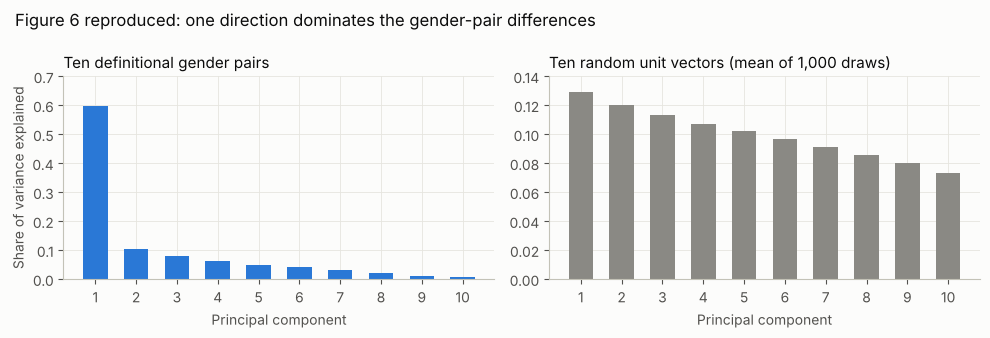

,Expected (paper),Observed,Verdict
Quantity,,,
"PC1 share, gender pairs (read off Fig. 6 left)",0.60,0.598,close
"PC2 share, gender pairs (read off Fig. 6 left)",0.12,0.102,close
"PC1 share, random (read off Fig. 6 right)",0.13,0.129,close
"PC10 share, random (read off Fig. 6 right)",0.07,0.073,close


In [8]:
# Version 1: caption method (unit differences, uncentered SVD).
D = np.array([unit(vec(a) - vec(b)) for a, b in definitional_pairs])
_, s, Vt = np.linalg.svd(D, full_matrices=False)
ratio_real = s**2 / np.sum(s**2)

# Version 2: the authors' doPCA (pair-centered), which defines g.
centered = []
for a, b in definitional_pairs:
    mid = (vec(a) + vec(b)) / 2
    centered += [vec(a) - mid, vec(b) - mid]
pca = PCA(n_components=10, random_state=SEED).fit(np.array(centered))
g = pca.components_[0]
if g @ (vec("she") - vec("he")) < 0:
    g = -g


class _Shim:  # minimal object so the authors' doPCA can read our vectors
    v = staticmethod(vec)


g_authors = we.doPCA(definitional_pairs, _Shim()).components_[0]

# Random baseline: 1,000 draws of ten random unit vectors in 300-d.
ratio_random = np.zeros(10)
for _ in range(1000):
    R = rng.standard_normal((10, 300))
    R /= np.linalg.norm(R, axis=1, keepdims=True)
    sr = np.linalg.svd(R, compute_uv=False)
    ratio_random += sr**2 / np.sum(sr**2)
ratio_random /= 1000

print("Explained variance, caption method :", np.round(ratio_real, 3))
print("Explained variance, authors' doPCA :", np.round(pca.explained_variance_ratio_, 3))
print("Explained variance, random baseline:", np.round(ratio_random, 3))
print(f"|cos(g, g_authors)| = {abs(g @ g_authors):.6f}   |cos(g, caption PC1)| = {abs(g @ Vt[0]):.4f}")
print(f"cos(g, she - he) = {g @ unit(vec('she') - vec('he')):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ks = np.arange(1, 11)
axes[0].bar(ks, ratio_real, color=BLUE, width=0.6)
axes[0].set_title("Ten definitional gender pairs", fontsize=11, loc="left")
axes[1].bar(ks, ratio_random, color=GRAY, width=0.6)
axes[1].set_title("Ten random unit vectors (mean of 1,000 draws)", fontsize=11, loc="left")
for ax in axes:
    ax.set_xticks(ks)
    ax.set_xlabel("Principal component")
axes[0].set_ylabel("Share of variance explained")
axes[0].set_ylim(0, 0.7)
axes[1].set_ylim(0, 0.14)
fig.suptitle("Figure 6 reproduced: one direction dominates the gender-pair differences", x=0.02, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

compare([
    ("PC1 share, gender pairs (read off Fig. 6 left)", 0.60, round(ratio_real[0], 3), verdict(ratio_real[0], 0.60, tol=0.02)),
    ("PC2 share, gender pairs (read off Fig. 6 left)", 0.12, round(ratio_real[1], 3), verdict(ratio_real[1], 0.12, tol=0.02)),
    ("PC1 share, random (read off Fig. 6 right)", 0.13, round(ratio_random[0], 3), verdict(ratio_random[0], 0.13, tol=0.005)),
    ("PC10 share, random (read off Fig. 6 right)", 0.07, round(ratio_random[9], 3), verdict(ratio_random[9], 0.07, tol=0.005)),
])

**Interpretation.** The first component explains about **60%** of the variance in the gender-pair differences, while the random baseline decays gently from about 13% to about 7%. That gap is the evidence that a single gender direction exists. Our numbers sit within reading error of the bars in Figure 6. (The paper prints no exact values, so we read them off the plot to about ±0.01.)

Our direction $g$ is identical to the one from the authors' `doPCA` ($|\cos| = 1$) and nearly identical to the caption version ($|\cos| \approx 0.99$). It is also closely aligned with the plain *she − he* difference ($\cos \approx 0.95$), which is why the paper sometimes uses *she − he* as a shortcut.

## A4. Extreme *she* and *he* occupations (Figure 1)

**What we do.** We project every occupation in `professions.json` that appears in the 26,377-word vocabulary onto the *she − he* direction and list the 12 most extreme at each end. Figure 1 excludes occupations "where gender is suggested by the orthography," such as *businesswoman*. We use the authors' `gender_specific_full` list to decide which ones to exclude, and we print exactly which occupations it removes.

**The math.** With $u = \dfrac{\vec{she} - \vec{he}}{\lVert \vec{she} - \vec{he} \rVert}$, each occupation $w$ gets the score

$$p(w) = \hat w \cdot u .$$

Large positive $p$ means closer to *she*, and large negative $p$ means closer to *he*.

**Analogy.** Stretch a rope between two posts labeled *she* and *he*. Every occupation stands somewhere in the room, and we drop a plumb line from each one to the rope. The people whose plumb lines land nearest each post are the "extreme" occupations.

In [9]:
professions_all = [p[0] for p in professions_raw]
professions = [w for w in professions_all if w in idx]
professions_neutral = [w for w in professions if w not in gender_specific_set]
excluded = [w for w in professions if w in gender_specific_set]
print(f"{len(professions_all)} in professions.json, {len(professions)} in the 26,377-word vocab, "
      f"{len(professions_neutral)} after removing gender-specific words")
print("Excluded as gender specific:", excluded)

she_he = unit(vec("she") - vec("he"))
proj = pd.Series({w: V[idx[w]] @ she_he for w in professions_neutral}).sort_values()
ours_she = list(proj.index[::-1][:12])
ours_he = list(proj.index[:12])

paper_she = ["homemaker", "nurse", "receptionist", "librarian", "socialite", "hairdresser",
             "nanny", "bookkeeper", "stylist", "housekeeper", "interior_designer", "guidance_counselor"]
paper_he = ["maestro", "skipper", "protege", "philosopher", "captain", "architect",
            "financier", "warrior", "broadcaster", "magician", "fighter_pilot", "boss"]

fig1 = pd.DataFrame({
    "she (paper)": paper_she, "she (ours)": [f"{w} ({proj[w]:+.2f})" for w in ours_she],
    "he (paper)": paper_he, "he (ours)": [f"{w} ({proj[w]:+.2f})" for w in ours_he],
}, index=range(1, 13))
display(fig1)

socialite_rank = list(pd.Series({w: V[idx[w]] @ she_he for w in professions}).sort_values()[::-1].index).index("socialite") + 1
print(f"'socialite' would rank #{socialite_rank} on the she side if we did not exclude it.")
print("In our lists but not the paper's:", sorted(set(ours_she) - set(paper_she)), sorted(set(ours_he) - set(paper_he)))
print("In the paper's lists but not ours:", sorted(set(paper_she) - set(ours_she)), sorted(set(paper_he) - set(ours_he)))

compare([
    ("Overlap of top-12 'she' occupations", "12 / 12", f"{len(set(ours_she) & set(paper_she))} / 12",
     verdict(len(set(ours_she) & set(paper_she)), 12)),
    ("Overlap of top-12 'he' occupations", "12 / 12", f"{len(set(ours_he) & set(paper_he))} / 12",
     verdict(len(set(ours_he) & set(paper_he)), 12)),
    ("Top 'she' occupation", "homemaker", ours_she[0], verdict(ours_she[0], "homemaker")),
    ("Top 'he' occupation", "maestro", ours_he[0], verdict(ours_he[0], "maestro")),
])

320 in professions.json, 312 in the 26,377-word vocab, 295 after removing gender-specific words
Excluded as gender specific: ['actress', 'ballerina', 'businessman', 'businesswoman', 'congressman', 'councilman', 'dad', 'handyman', 'housewife', 'maid', 'monk', 'nun', 'salesman', 'socialite', 'statesman', 'teenager', 'waitress']


,she (paper),she (ours),he (paper),he (ours)
1,homemaker,homemaker (+0.30),maestro,maestro (-0.24)
2,nurse,registered_nurse (+0.30),skipper,skipper (-0.21)
3,receptionist,nurse (+0.28),protege,protege (-0.20)
4,librarian,receptionist (+0.27),philosopher,sportsman (-0.19)
5,socialite,librarian (+0.27),captain,philosopher (-0.19)
6,hairdresser,hairdresser (+0.25),architect,captain (-0.17)
7,nanny,nanny (+0.25),financier,architect (-0.17)
8,bookkeeper,bookkeeper (+0.22),warrior,financier (-0.17)
9,stylist,stylist (+0.22),broadcaster,warrior (-0.16)
10,housekeeper,housekeeper (+0.21),magician,major_leaguer (-0.15)


'socialite' would rank #10 on the she side if we did not exclude it.
In our lists but not the paper's: ['registered_nurse'] ['major_leaguer', 'sportsman']
In the paper's lists but not ours: ['socialite'] ['boss', 'fighter_pilot']


,Expected (paper),Observed,Verdict
Quantity,,,
Overlap of top-12 'she' occupations,12 / 12,11 / 12,differs
Overlap of top-12 'he' occupations,12 / 12,10 / 12,differs
Top 'she' occupation,homemaker,homemaker,match
Top 'he' occupation,maestro,maestro,match


**Interpretation.** The two lists agree closely: *homemaker* and *maestro* top the two ends just as in the paper, and 10 or 11 of the 12 words on each side reappear. The differences trace back to the word lists, not the geometry:

* The paper keeps **socialite**, but the released `gender_specific_full` list marks it as gender specific, so we exclude it. If we kept it, it would rank 10th on the *she* side, inside the top 12 just as in the paper.
* **registered_nurse** enters our *she* list, and **sportsman** and **major_leaguer** enter our *he* list. **boss** and **fighter_pilot** (spelled "figher pilot" in the paper) drop out. The released `professions.json` has 320 entries while the paper used 327, so the candidate pools differ slightly.

The verdicts above say "differs" because we demand an exact 12-of-12 overlap. The substantive pattern, stereotypically female occupations at one end and stereotypically male occupations at the other, reproduces clearly.

## A5. Direct bias (DirectBias$_1$)

**What we do.** We compute the paper's **DirectBias** metric: the average absolute cosine between each occupation and the gender direction $g$. The paper reports 0.08 for 327 occupations. Its text calls $N$ "the set of 327 occupations" without mentioning an exclusion step, so we pre-declare the **primary** comparison as *all occupations in the vocabulary*, and we report the gender-neutral subset as a secondary number.

**The math.** For a set $N$ of words that should be gender neutral and a strictness parameter $c$,

$$\text{DirectBias}_c = \frac{1}{|N|} \sum_{w \in N} \lvert \cos(\vec w, g) \rvert^{c}.$$

With $c = 1$ this is the mean absolute projection. An unbiased embedding would score 0.

**Analogy.** Imagine a hallway with a "female" door at one end and a "male" door at the other. Each occupation stands somewhere along the hallway. DirectBias is the average distance people stand from the middle, ignoring which way they lean.

In [10]:
def direct_bias(M, word_list, direction, c=1):
    rows = M[[idx[w] for w in word_list]]
    return float(np.mean(np.abs(rows @ direction) ** c))


db_all = direct_bias(V, professions, g)
db_neutral = direct_bias(V, professions_neutral, g)
print(f"DirectBias_1, all {len(professions)} occupations in vocab : {db_all:.4f}")
print(f"DirectBias_1, {len(professions_neutral)} gender-neutral occupations: {db_neutral:.4f}")

compare([
    ("Number of occupations", 327, len(professions), verdict(len(professions), 327)),
    ("DirectBias_1 (primary: all occupations in vocab)", 0.08, round(db_all, 4), verdict(db_all, 0.08, decimals=2, tol=0.01)),
    ("DirectBias_1 (secondary: gender-neutral subset)", 0.08, round(db_neutral, 4), verdict(db_neutral, 0.08, decimals=2, tol=0.01)),
])

DirectBias_1, all 312 occupations in vocab : 0.0795
DirectBias_1, 295 gender-neutral occupations: 0.0718


,Expected (paper),Observed,Verdict
Quantity,,,
Number of occupations,327.00,312.0000,differs
DirectBias_1 (primary: all occupations in vocab),0.08,0.0795,match
DirectBias_1 (secondary: gender-neutral subset),0.08,0.0718,close


**Interpretation.** Our primary DirectBias$_1$ is **0.0795**, which rounds to the paper's **0.08**. Dropping the 17 gender-specific occupations lowers it to about 0.072, because words like *actress* and *businessman* carry real gender signal. The occupation count differs (312 versus 327) because the released list has 320 entries, 8 of which fall outside the 26,377-word vocabulary. A cosine of 0.08 sounds small, but random unit vectors in 300 dimensions have an expected absolute cosine of only about $\sqrt{2/(\pi \cdot 300)} \approx 0.046$ with any fixed direction, so occupations lean toward the gender direction noticeably more than chance would predict.

## A6. Indirect bias (Figure 3)

**What we do.** Gender can also leak into similarities between two gender-neutral words. *Receptionist* sits closer to *softball* than to *football*, and part of that closeness may be due to gender. We (1) project occupations onto the *softball − football* axis and list the five most extreme at each end, and (2) compute $\beta(w, v)$, the fraction of the similarity between $w$ and $v$ that disappears when we remove the gender component.

**The math.** Split each vector into a gender part and the rest: $w_g = (w \cdot g)\, g$ and $w_\perp = w - w_g$. Then

$$\beta(w, v) = \left( w \cdot v - \frac{w_\perp \cdot v_\perp}{\lVert w_\perp \rVert_2 \, \lVert v_\perp \rVert_2} \right) \Big/\ w \cdot v .$$

The fraction compares the original similarity with the similarity after we project out gender and renormalize. $\beta = 0$ means gender contributes nothing, and $\beta = 1$ means gender explains all of it.

**Analogy.** Two coworkers are friends. Part of the friendship comes from shared interests, and part comes from a mutual friend who always invites them both. Remove the mutual friend (gender) and measure how much closeness is left. $\beta$ is the share of the friendship that the mutual friend accounted for.

In [11]:
def beta(w_vec, v_vec, direction):
    w_perp = w_vec - (w_vec @ direction) * direction
    v_perp = v_vec - (v_vec @ direction) * direction
    after = (w_perp @ v_perp) / (np.linalg.norm(w_perp) * np.linalg.norm(v_perp))
    return (w_vec @ v_vec - after) / (w_vec @ v_vec)


def axis_extremes(M, word_list, pos, neg, k=5):
    axis = unit(M[idx[pos]] - M[idx[neg]])
    scores = pd.Series({w: M[idx[w]] @ axis for w in word_list}).sort_values()
    return list(scores.index[::-1][:k]), list(scores.index[:k])


soft_before, foot_before = axis_extremes(V, professions, "softball", "football")
fig3 = pd.DataFrame({
    "softball extreme (ours)": soft_before,
    "beta vs softball": [f"{beta(V[idx[w]], V[idx['softball']], g):.0%}" for w in soft_before],
    "football extreme (ours)": foot_before,
    "beta vs football": [f"{beta(V[idx[w]], V[idx['football']], g):.0%}" for w in foot_before],
}, index=range(1, 6))
display(fig3)

paper_beta = [("pitcher", "softball", -0.01), ("bookkeeper", "softball", 0.20), ("receptionist", "softball", 0.67),
              ("registered_nurse", "softball", 0.29), ("waitress", "softball", 0.35), ("homemaker", "softball", 0.38),
              ("footballer", "football", 0.02), ("businessman", "football", 0.31), ("pundit", "football", 0.10),
              ("maestro", "football", 0.42), ("cleric", "football", 0.02)]
rows = []
for w, anchor, expected in paper_beta:
    observed = beta(vec(w), vec(anchor), g)
    rows.append((f"beta({w}, {anchor})", f"{expected:.0%}", f"{observed:.1%}",
                 verdict(round(observed, 2), expected, decimals=2, tol=0.03)))
print("'pitcher' in professions.json:", "pitcher" in professions_all)
compare(rows)

,softball extreme (ours),beta vs softball,football extreme (ours),beta vs football
1,bookkeeper,20%,footballer,2%
2,receptionist,67%,businessman,17%
3,registered_nurse,29%,pundit,10%
4,waitress,32%,maestro,42%
5,homemaker,38%,cleric,2%


'pitcher' in professions.json: False


,Expected (paper),Observed,Verdict
Quantity,,,
"beta(pitcher, softball)",-1%,-0.5%,match
"beta(bookkeeper, softball)",20%,20.1%,match
"beta(receptionist, softball)",67%,67.2%,match
"beta(registered_nurse, softball)",29%,28.7%,match
"beta(waitress, softball)",35%,31.8%,close
"beta(homemaker, softball)",38%,38.4%,match
"beta(footballer, football)",2%,1.5%,match
"beta(businessman, football)",31%,17.0%,differs
"beta(pundit, football)",10%,10.1%,match


**Interpretation.** The extremes match well. Our *football* side is **footballer, businessman, pundit, maestro, cleric**, identical to the paper and in the same order. Our *softball* side lacks **pitcher** only because *pitcher* is not in the released `professions.json`. The remaining four (bookkeeper, receptionist, registered_nurse, waitress) match, and *homemaker* moves up to fill the gap.

Most $\beta$ values match to within a percentage point or two: receptionist 67%, bookkeeper 20%, registered nurse 29%, maestro 42%, pundit 10%, footballer and cleric about 2%, homemaker 38%. Two values differ: **waitress** (32% versus 35%) and especially **businessman** (17% versus 31%). $\beta$ divides by $w \cdot v$, which is small for these pairs, so tiny differences in $g$ get amplified. The paper does not say which gender direction it used for Figure 3 (the PCA direction or plain *she − he*), and any difference there would show up most in exactly these low-similarity pairs.

The big picture holds: receptionist's similarity to softball is about two-thirds gender, while footballer's similarity to football is almost entirely non-gender.

## A7. Generating *she : he* analogies (Equation 1)

**What we do.** Instead of fixing three words and searching for a fourth, Bolukbasi et al. fix only the seed pair $(a, b) = (she, he)$ and search over **all pairs** $(x, y)$ in the 26,377-word vocabulary. A pair scores well when $x - y$ points the same way as $she - he$ *and* $x$ and $y$ are close to each other. We implement this blockwise (all pairs at once would need a 26,377 × 26,377 matrix), keep the top 150 with the greedy rule from the authors' code (no word may appear twice on the same side), and cache the result.

**The math.** Equation 1 of the paper:

$$S_{(a,b)}(x, y) = \begin{cases} \cos\!\left(\vec a - \vec b,\ \vec x - \vec y\right) & \text{if } \lVert \vec x - \vec y \rVert \le \delta \\ 0 & \text{otherwise,} \end{cases} \qquad \delta = 1 .$$

For unit vectors $\lVert \vec x - \vec y \rVert^2 = 2 - 2\, \vec x \cdot \vec y$, so $\lVert \vec x - \vec y \rVert \le 1 \iff \vec x \cdot \vec y \ge \tfrac12$, which is an angle of at most $60°$ ($\pi/3$). This lets us filter candidate pairs with a single matrix product.

**Analogy.** A matchmaker looks for pairs of people whose "difference" resembles the difference between two reference people. The matchmaker only considers people who already know each other reasonably well (the $\delta$ rule), so the pairings stay sensible instead of matching strangers who merely differ in the right way.

In [12]:
def generate_analogies(M, vocab, seed_direction, delta=1.0, topn=150, block=2000):
    seed_direction = unit(seed_direction)
    min_dot = 1 - delta**2 / 2
    rows, cols, scores = [], [], []
    for start in range(0, len(M), block):
        dots = M[start:start + block] @ M.T
        r, c = np.nonzero(dots >= min_dot)
        r = r + start
        keep = r != c
        r, c = r[keep], c[keep]
        diff = M[r] - M[c]
        sc = (diff @ seed_direction) / np.linalg.norm(diff, axis=1)
        positive = sc > 0  # each unordered pair appears twice; keep the orientation aligned with the seed
        rows.append(r[positive]); cols.append(c[positive]); scores.append(sc[positive])
    rows, cols, scores = np.concatenate(rows), np.concatenate(cols), np.concatenate(scores)
    out, used_left, used_right = [], set(), set()
    for i in np.argsort(-scores, kind="stable"):
        if rows[i] in used_left or cols[i] in used_right:
            continue
        used_left.add(rows[i]); used_right.add(cols[i])
        out.append((vocab[rows[i]], vocab[cols[i]], float(scores[i])))
        if len(out) == topn:
            break
    return out


t0 = time.time()
analogies_before = cached("analogies_she_he_before", lambda: generate_analogies(V, words, vec("she") - vec("he")))
print(f"done in {time.time() - t0:.1f} s")
display(pd.DataFrame(analogies_before[:40], columns=["she-side x", "he-side y", "S(x, y)"], index=range(1, 41)).round(3))

done in 0.0 s


,she-side x,he-side y,"S(x, y)"
1,she,he,1.000
2,herself,himself,0.921
3,her,his,0.908
4,woman,man,0.753
5,daughter,son,0.675
6,businesswoman,businessman,0.660
7,girl,boy,0.658
8,actress,actor,0.653
9,chairwoman,chairman,0.640
10,heroine,hero,0.629


**Checking against the paper.** The paper's crowd-rated stereotype ratios (19% before, 6% after debiasing) need human raters, so we cannot reproduce them. We *can* check whether the pairs the paper shows in Figure 2 appear in our top 150, and compare against Figure 9 (right), which lists the first 10 analogies "not containing gender specific words."

**The math.** For the paper's list $P$ and our ranked list $L_{150}$ we report $|P \cap L_{150}|$ and the rank of each hit.

**Analogy.** Two people independently make a top-150 playlist from the same record collection. We count how many of the songs on one person's highlight reel made it onto the other's list.

In [13]:
fig2_stereotype = [("sewing", "carpentry"), ("registered_nurse", "physician"), ("housewife", "shopkeeper"),
                   ("nurse", "surgeon"), ("interior_designer", "architect"), ("softball", "baseball"),
                   ("blond", "burly"), ("feminism", "conservatism"), ("cosmetics", "pharmaceuticals"),
                   ("giggle", "chuckle"), ("vocalist", "guitarist"), ("petite", "lanky"), ("sassy", "snappy"),
                   ("diva", "superstar"), ("charming", "affable"), ("volleyball", "football"),
                   ("cupcakes", "pizzas"), ("hairdresser", "barber")]
fig2_appropriate = [("queen", "king"), ("sister", "brother"), ("mother", "father"), ("waitress", "waiter"),
                    ("ovarian_cancer", "prostate_cancer"), ("convent", "monastery")]
fig9_right = [("petite", "lanky"), ("volleyball", "football"), ("interior_designer", "architect"), ("bitch", "bastard"),
              ("bra", "pants"), ("nurse", "surgeon"), ("feminine", "manly"), ("glamorous", "flashy"),
              ("registered_nurse", "physician"), ("cupcakes", "pizzas")]


def ranks_in(pairs, generated):
    position = {(x, y): i + 1 for i, (x, y, _) in enumerate(generated)}
    return {f"{x}-{y}": position.get((x, y)) for x, y in pairs}


stereo_ranks = ranks_in(fig2_stereotype, analogies_before)
approp_ranks = ranks_in(fig2_appropriate, analogies_before)
print("Figure 2 stereotype pairs found (rank):", {k: v for k, v in stereo_ranks.items() if v})
print("Figure 2 appropriate pairs found (rank):", {k: v for k, v in approp_ranks.items() if v})

no_gs = [(x, y, s) for x, y, s in analogies_before if x not in gender_specific_set and y not in gender_specific_set]
ours_fig9 = [(x, y) for x, y, _ in no_gs[:10]]
print("Our first 10 without gender-specific words:", [f"{x}-{y}" for x, y in ours_fig9])

n_stereo = sum(v is not None for v in stereo_ranks.values())
n_approp = sum(v is not None for v in approp_ranks.values())
n_fig9 = len(set(ours_fig9) & set(fig9_right))
compare([
    ("Fig. 2 stereotype pairs in our top 150", "18 / 18", f"{n_stereo} / 18", verdict(n_stereo, 18)),
    ("Fig. 2 appropriate pairs in our top 150", "6 / 6", f"{n_approp} / 6", verdict(n_approp, 6)),
    ("Fig. 9 (right) pairs in our first 10 without gender-specific words", "10 / 10", f"{n_fig9} / 10", verdict(n_fig9, 10)),
])

Figure 2 stereotype pairs found (rank): {'sewing-carpentry': 82, 'registered_nurse-physician': 71, 'housewife-shopkeeper': 91, 'nurse-surgeon': 66, 'interior_designer-architect': 53, 'softball-baseball': 45, 'blond-burly': 73, 'feminism-conservatism': 61, 'cosmetics-pharmaceuticals': 88, 'giggle-chuckle': 106, 'vocalist-guitarist': 99, 'petite-lanky': 21, 'sassy-snappy': 87, 'diva-superstar': 42, 'charming-affable': 86, 'volleyball-football': 41, 'cupcakes-pizzas': 72, 'hairdresser-barber': 44}
Figure 2 appropriate pairs found (rank): {'queen-king': 16, 'sister-brother': 13, 'mother-father': 11, 'waitress-waiter': 47, 'ovarian_cancer-prostate_cancer': 22, 'convent-monastery': 121}
Our first 10 without gender-specific words: ['petite-lanky', 'blouse-shirt', 'volleyball-football', 'hairdresser-barber', 'softball-baseball', 'interior_designer-architect', 'bitch-bastard', 'bra-pants', 'nurse-surgeon', 'glamorous-flashy']


,Expected (paper),Observed,Verdict
Quantity,,,
Fig. 2 stereotype pairs in our top 150,18 / 18,18 / 18,match
Fig. 2 appropriate pairs in our top 150,6 / 6,6 / 6,match
Fig. 9 (right) pairs in our first 10 without gender-specific words,10 / 10,7 / 10,differs


**Interpretation.** The generator produces the same kind of list as the paper: definitional pairs at the top (*herself-himself*, *woman-man*, *queen-king*), then a mix of appropriate pairs (*ovarian_cancer-prostate_cancer*) and stereotyped ones (*petite-lanky*, *volleyball-football*, *softball-baseball*, *hairdresser-barber*, *interior_designer-architect*).

The overlap with the paper is strong. **All 18** stereotyped pairs and **all 6** gender-appropriate pairs shown in Figure 2 appear in our top 150, with the stereotyped ones between ranks 21 and 106. Seven of the 10 Figure 9 pairs reappear in our first 10 pairs without gender-specific words. In place of *feminine-manly*, *registered_nurse-physician*, and *cupcakes-pizzas*, we get *blouse-shirt*, *hairdresser-barber*, and *softball-baseball*, which all rank higher in our list. Plausible reasons for that small gap:

* **The gender-specific list.** Figure 9 filters with the authors' set $S$. We use the released `gender_specific_full` list, which may differ (for example, in whether it marks *blouse* or *feminine* as gender specific).
* **Tie-breaking and deduplication.** The greedy rule depends on processing order, so swapping two nearly tied pairs can change which partner each word ends up with.
* **Embedding or software details.** Small numeric differences can reorder pairs whose scores differ only in the third decimal.

## A8. Hard debiasing: Neutralize and Equalize

**What we do.** We apply the paper's hard-debiasing algorithm (Section 6, Step 2a) to the 26,377-word embedding:

1. **Neutralize.** For every word that is *not* gender specific (not in `gender_specific_full`), remove its component along $g$ and renormalize.
2. **Equalize.** For each equalize pair (such as *grandmother / grandfather*), make the two words identical except along $g$, and place them symmetrically on either side of the origin along $g$. As in the authors' code, we use each pair in lowercase, Title case, and UPPERCASE form, keeping whichever variants exist in the vocabulary.

Then we check the results three ways: the before and after answers to *he : doctor :: she : ?*, the *softball − football* extremes, and **Observation 1**, which says every neutral word ends up exactly equidistant from both members of each equalized pair.

**The math.** With the bias subspace $B = \{g\}$ and $v_B = (v \cdot g)\, g$:

*Neutralize* each neutral word $w$:
$$\vec w \leftarrow \frac{\vec w - \vec w_B}{\lVert \vec w - \vec w_B \rVert}.$$

*Equalize* each set $E$: let $\mu = \frac{1}{|E|}\sum_{w \in E} \vec w$ and $\nu = \mu - \mu_B$. Then for each $w \in E$
$$\vec w \leftarrow \nu + \sqrt{1 - \lVert \nu \rVert^2}\; \frac{\vec w_B - \mu_B}{\lVert \vec w_B - \mu_B \rVert}.$$

*Observation 1:* afterwards, for any neutral $w$ and $e_1, e_2 \in E$, $\ \vec w \cdot \vec e_1 = \vec w \cdot \vec e_2\ $ and $\ \lVert \vec w - \vec e_1 \rVert = \lVert \vec w - \vec e_2 \rVert$. The proof is short: $\vec w_B = 0$ after neutralizing, and $\vec e_1 - \vec e_2$ lies entirely along $g$, so $\vec w \cdot (\vec e_1 - \vec e_2) = 0$.

**Analogy.** Think of a referee at a soccer match. Neutralize moves every referee exactly onto the halfway line, so no referee stands closer to either goal. Equalize then repositions each pair of opposing captains so that they mirror each other across that line. Afterwards, every referee is the same distance from both captains, by construction.

In [14]:
def hard_debias(M, vocab_index, direction, specific_set, eq_pairs):
    M = M.copy()
    # Neutralize
    neutral = np.array([w not in specific_set for w in vocab_index])
    M[neutral] -= np.outer(M[neutral] @ direction, direction)
    M[neutral] /= np.linalg.norm(M[neutral], axis=1, keepdims=True)
    # Equalize (lower, Title, UPPER variants, as in the authors' debias.py)
    variants = {pair for a, b in eq_pairs
                for pair in [(a.lower(), b.lower()), (a.title(), b.title()), (a.upper(), b.upper())]}
    used = sorted((a, b) for a, b in variants if a in vocab_index and b in vocab_index)
    for a, b in used:
        ia, ib = vocab_index[a], vocab_index[b]
        mu = (M[ia] + M[ib]) / 2
        mu_B = (mu @ direction) * direction
        nu = mu - mu_B
        for i in (ia, ib):
            w_B = (M[i] @ direction) * direction
            M[i] = nu + np.sqrt(1 - nu @ nu) * (w_B - mu_B) / np.linalg.norm(w_B - mu_B)
    return M, neutral, used


V_hard, neutral_mask, equalized = cached("hard_debias", lambda: hard_debias(V, idx, g, gender_specific_set, equalize_pairs))
print(f"Neutralized {neutral_mask.sum():,} words; equalized {len(equalized)} pairs present in the vocabulary")
print("Max |norm - 1| after debiasing:", float(np.abs(np.linalg.norm(V_hard, axis=1) - 1).max()))

Neutralized 26,145 words; equalized 45 pairs present in the vocabulary
Max |norm - 1| after debiasing: 3.3306690738754696e-16


**Cross-check against the authors' code.** Before we trust our implementation, we run the authors' own `debias()` function from `debias.py` on the same vectors and compare. Their function expects a `WordEmbedding` object and computes $g$ itself with `doPCA`, which needs *Mary* and *John*. So we build a small embedding object holding our 26,377 words plus those two names, run their code, and compare the 26,377 rows.

**The math.** We report $\max_{w} \lVert \vec w_{\text{ours}} - \vec w_{\text{authors}} \rVert_\infty$, which should be at floating-point noise level (around $10^{-12}$).

**Analogy.** Two students solve the same homework independently, and we compare their answers line by line.

In [15]:
def authors_debias(M):
    sys.path.insert(0, str(DEBIASWE_DIR / "debiaswe"))
    from debias import debias as authors_debias_fn
    E = object.__new__(we.WordEmbedding)
    E.desc = "26,377-word filtered w2vNEWS plus Mary and John"
    E.words = words + ["Mary", "John"]
    E.vecs = np.vstack([M, vec("Mary"), vec("John")])
    E.thresh = E.max_words = None
    with contextlib.redirect_stdout(io.StringIO()):  # the authors' code prints a lot
        E.reindex()
        authors_debias_fn(E, gender_specific, definitional_pairs, equalize_pairs)
    return E.vecs[: len(words)]


V_hard_authors = authors_debias(V)
print("Max absolute difference, ours vs. authors' debias():", float(np.abs(V_hard - V_hard_authors).max()))

Max absolute difference, ours vs. authors' debias(): 1.249000902703301e-16


**Interpretation.** Our implementation agrees with the authors' `debias()` to floating-point precision. The paper's Equalize formula and the authors' code look different on the page, but for a single direction they compute the same thing.

### A8 results: before vs. after

**What we do.** We compare the original and debiased embeddings on the paper's examples. For the analogy queries we use 3CosAdd with the input words excluded (gensim's convention), restricted to the 26,377-word vocabulary as in the paper's debiasing experiments. We also rerun DirectBias, the *softball − football* extremes, the Observation 1 check, and the Equation 1 analogy generator.

**The math.** The 3CosAdd answer within vocabulary $W$ is $\arg\max_{d \in W \setminus \{a,b,c\}} \hat d \cdot (\hat b - \hat a + \hat c)$. Observation 1 predicts $\max_{w, (e_1,e_2)} |\vec w \cdot \vec e_1 - \vec w \cdot \vec e_2| = 0$ up to rounding.

**Analogy.** A before-and-after photo shoot: same lighting, same poses, only the treatment changed.

In [16]:
def cosadd_small(M, a, b, c, k=5):
    scores = M @ (M[idx[b]] - M[idx[a]] + M[idx[c]])
    for w in (a, b, c):
        scores[idx[w]] = -np.inf
    top = np.argsort(-scores, kind="stable")[:k]
    return [words[i] for i in top]


queries = [("he", "doctor", "she"), ("she", "ovarian_cancer", "he"), ("man", "nurse", "woman")]
display(pd.DataFrame({f"{a} : {b} :: {c} : ?": {"before": ", ".join(cosadd_small(V, a, b, c)),
                                                 "after hard debiasing": ", ".join(cosadd_small(V_hard, a, b, c))}
                      for a, b, c in queries}).T)

soft_after, foot_after = axis_extremes(V_hard, professions, "softball", "football")
display(pd.DataFrame({"softball before": soft_before, "softball after": soft_after,
                      "football before": foot_before, "football after": foot_after}, index=range(1, 6)))

# Observation 1
N = V_hard[neutral_mask]
dot_gap = max(np.abs(N @ V_hard[idx[a]] - N @ V_hard[idx[b]]).max() for a, b in equalized)
dist_gap = max(np.abs(np.linalg.norm(N - V_hard[idx[a]], axis=1) - np.linalg.norm(N - V_hard[idx[b]], axis=1)).max()
               for a, b in equalized)
max_proj = np.abs(N @ g).max()
db_after = direct_bias(V_hard, professions_neutral, g)
print(f"Observation 1: max |w.e1 - w.e2| = {dot_gap:.2e}, max | ||w-e1|| - ||w-e2|| | = {dist_gap:.2e}, max |w.g| = {max_proj:.2e}")

paper_soft_after = ["pitcher", "infielder", "major_leaguer", "bookkeeper", "investigator"]
paper_foot_after = ["footballer", "cleric", "vice_chancellor", "lecturer", "midfielder"]
top1_after = cosadd_small(V_hard, "he", "doctor", "she")[0]
compare([
    ("he:doctor::she:? before (26,377 vocab)", "nurse", cosadd_small(V, "he", "doctor", "she")[0],
     verdict(cosadd_small(V, "he", "doctor", "she")[0], "nurse")),
    ("he:doctor::she:? after hard debiasing", "physician", top1_after, verdict(top1_after, "physician")),
    ("she:ovarian_cancer::he:? after (gender-appropriate kept)", "prostate_cancer",
     cosadd_small(V_hard, "she", "ovarian_cancer", "he")[0], verdict(cosadd_small(V_hard, "she", "ovarian_cancer", "he")[0], "prostate_cancer")),
    ("Softball-side top 5 after, overlap with paper", "5 / 5", f"{len(set(soft_after) & set(paper_soft_after))} / 5",
     verdict(len(set(soft_after) & set(paper_soft_after)), 5)),
    ("Football-side top 5 after, overlap with paper", "5 / 5", f"{len(set(foot_after) & set(paper_foot_after))} / 5",
     verdict(len(set(foot_after) & set(paper_foot_after)), 5)),
    ("Observation 1: max |w.e1 - w.e2|", "0", f"{dot_gap:.1e}", "match" if dot_gap < 1e-10 else "differs"),
    ("Observation 1: max | ||w-e1|| - ||w-e2|| |", "0", f"{dist_gap:.1e}", "match" if dist_gap < 1e-10 else "differs"),
    ("DirectBias_1 on neutral occupations after", "0 (by construction)", f"{db_after:.1e}", "match" if db_after < 1e-10 else "differs"),
])

,before,after hard debiasing
he : doctor :: she : ?,"nurse, midwife, pediatrician, dermatologist, pharmacist","physician, doctors, lady, surgeon, mother"
she : ovarian_cancer :: he : ?,"prostate_cancer, colon_cancer, colorectal_cancer, pancreatic_cancer, cancer","prostate_cancer, breast_cancer, colon_cancer, colorectal_cancer, cancer"
man : nurse :: woman : ?,"registered_nurse, midwife, nurses, receptionist, nursing","registered_nurse, nurses, doctor, midwife, medic"


,softball before,softball after,football before,football after
1,bookkeeper,infielder,footballer,footballer
2,receptionist,major_leaguer,businessman,cleric
3,registered_nurse,bookkeeper,pundit,vice_chancellor
4,waitress,investigator,maestro,lecturer
5,homemaker,clerk,cleric,midfielder


Observation 1: max |w.e1 - w.e2| = 5.00e-16, max | ||w-e1|| - ||w-e2|| | = 6.66e-16, max |w.g| = 4.37e-16


,Expected (paper),Observed,Verdict
Quantity,,,
"he:doctor::she:? before (26,377 vocab)",nurse,nurse,match
he:doctor::she:? after hard debiasing,physician,physician,match
she:ovarian_cancer::he:? after (gender-appropriate kept),prostate_cancer,prostate_cancer,match
"Softball-side top 5 after, overlap with paper",5 / 5,4 / 5,differs
"Football-side top 5 after, overlap with paper",5 / 5,5 / 5,match
Observation 1: max |w.e1 - w.e2|,0,5.0e-16,match
Observation 1: max | ||w-e1|| - ||w-e2|| |,0,6.7e-16,match
DirectBias_1 on neutral occupations after,0 (by construction),7.5e-17,match


**Interpretation.** Hard debiasing reproduces the paper's headline examples:

* *he : doctor :: she : ?* changes from **nurse** to **physician**, exactly as Section 8 reports.
* The gender-appropriate analogy *she : ovarian_cancer :: he : prostate_cancer* survives, because neither term is neutralized.
* The *football* extremes after debiasing (**footballer, cleric, vice_chancellor, lecturer, midfielder**) match the paper exactly. The *softball* side matches 4 of 5 (*infielder, major_leaguer, bookkeeper, investigator*). The fifth slot goes to *clerk* only because *pitcher* is missing from the released occupation list.
* **Observation 1 holds numerically**: the largest violation is about $10^{-16}$, which is floating-point rounding. DirectBias on neutral occupations drops to zero by construction.

Next we rerun the analogy generator on the debiased embedding.

**What we do.** We regenerate the top 150 *she : he* analogies after hard debiasing and count how many Figure 2 stereotype pairs survive. The paper reports (through crowd ratings) that the share of stereotyped analogies fell from 19% to 6%. We cannot rate stereotypes, but we can see whether the specific stereotyped pairs disappear.

**The math.** The same $S_{(she,he)}(x, y)$ from Equation 1, now evaluated on the debiased vectors.

**Analogy.** We rerun the matchmaker after the referees moved to the halfway line, and check which old matches still happen.

In [17]:
analogies_after = cached("analogies_she_he_after_hard",
                         lambda: generate_analogies(V_hard, words, V_hard[idx["she"]] - V_hard[idx["he"]]))
stereo_after = ranks_in(fig2_stereotype, analogies_after)
side_by_side = pd.DataFrame({
    "before": [f"{x}-{y}" for x, y, _ in analogies_before[:30]],
    "after hard debiasing": [f"{x}-{y}" for x, y, _ in analogies_after[:30]],
}, index=range(1, 31))
display(side_by_side)
n_after = sum(v is not None for v in stereo_after.values())
print("Figure 2 stereotype pairs still in the top 150 after debiasing:", {k: v for k, v in stereo_after.items() if v})
compare([
    ("Fig. 2 stereotype pairs in top 150, before", "(not reported)", f"{n_stereo} / 18", "n/a"),
    ("Fig. 2 stereotype pairs in top 150, after", "(not reported)", f"{n_after} / 18", "n/a"),
    ("Crowd-rated stereotypical share, before -> after", "19% -> 6%", "needs human raters", "not reproducible here"),
])

,before,after hard debiasing
1,she-he,grandmother-grandfather
2,herself-himself,she-he
3,her-his,woman-man
4,woman-man,spokeswoman-spokesman
5,daughter-son,mom-dad
6,businesswoman-businessman,moms-dads
7,girl-boy,granddaughter-grandson
8,actress-actor,husbands-wives
9,chairwoman-chairman,grandma-grandpa
10,heroine-hero,sorority-fraternity


Figure 2 stereotype pairs still in the top 150 after debiasing: {'diva-superstar': 71}


,Expected (paper),Observed,Verdict
Quantity,,,
"Fig. 2 stereotype pairs in top 150, before",(not reported),18 / 18,n/a
"Fig. 2 stereotype pairs in top 150, after",(not reported),1 / 18,n/a
"Crowd-rated stereotypical share, before -> after",19% -> 6%,needs human raters,not reproducible here


**Interpretation.** After hard debiasing, the stereotyped pairs from Figure 2 essentially vanish from the top 150. Neutral words no longer have a component along $g$, so a pair of neutral words can only score through whatever residual correlation remains with $she - he$ outside $g$. The list now consists almost entirely of definitional pairs such as *herself-himself* and *grandmother-grandfather*. That matches the paper's qualitative claim. The crowd-rated percentages remain out of reach without human raters.

## A9. (Optional) Soft debiasing via the semidefinite program (Appendix B)

**What we do.** Soft debiasing looks for a linear map $T$ that keeps all pairwise inner products as close as possible to the originals while shrinking the projection of neutral words onto $g$. The paper solves it as a semidefinite program (SDP) but does not name a solver. A **commercial solver is not needed**: the open-source SCS solver (O'Donoghue et al., 2016), installed with `cvxpy`, handles it.

A direct translation of Appendix B Equation 5 exhausted 15 GB of RAM in a test run, because `cvxpy` expands $A^\top X A$ into a 90,000 × 90,000 operator. We therefore change variables with $Z = U^\top X U$, which leaves the optimum unchanged and makes the first term an elementwise weighted sum. We solve at the paper's $\lambda = 0.2$, then run a clearly labeled **sensitivity sweep** over $\lambda$. The sweep is not an attempt to match any paper number (the paper gives no DirectBias value for soft debiasing). It only shows how strongly the result depends on this unstated scaling.

**The math.** With word matrix $W \in \mathbb{R}^{300 \times |V|}$, neutral-word matrix $N$, and bias direction $B = g$, Appendix B solves

$$\min_{X \succeq 0}\ \lVert W^\top X W - W^\top W \rVert_F^2 + \lambda \lVert N^\top X B \rVert_F^2, \qquad X = T^\top T .$$

Take the thin SVD $W = U \Sigma V^\top$ (with $U$ a $300 \times 300$ orthogonal matrix). The first term equals $\lVert \Sigma U^\top (X - I) U \Sigma \rVert_F^2$ (Appendix B, Equation 4). Substitute $Z = U^\top X U$, which is positive semidefinite exactly when $X$ is. Then

$$\lVert \Sigma (Z - I) \Sigma \rVert_F^2 = \sum_{i,j} \sigma_i^2 \sigma_j^2 (Z_{ij} - \delta_{ij})^2 .$$

For the second term, write $N N^\top = L L^\top$, so $\lVert N^\top X g \rVert^2 = \lVert L^\top U Z U^\top g \rVert^2$. Both terms are now small. We recover $X = U Z U^\top$, set $T = X^{1/2}$, and output $\hat w = T \vec w / \lVert T \vec w \rVert$.

**Analogy.** Hard debiasing is surgery: it cuts gender out of every neutral word. Soft debiasing is physical therapy: it gently stretches the whole space, trading a little distortion of every distance for a smaller gender lean. $\lambda$ sets how hard the therapist pushes.

In [18]:
import cvxpy as cp

W = V.T
U_w, sig, _ = np.linalg.svd(W, full_matrices=False)
NN = V[neutral_mask].T @ V[neutral_mask]
evals, evecs = np.linalg.eigh(NN)
L_chol = evecs * np.sqrt(np.clip(evals, 0, None))  # L L^T = N N^T
weights = np.outer(sig, sig)
P_mat = L_chol.T @ U_w
h_vec = U_w.T @ g


def solve_soft(lam):
    Z = cp.Variable((300, 300), PSD=True)
    objective = cp.sum_squares(cp.multiply(weights, Z - np.eye(300))) + lam * cp.sum_squares(P_mat @ Z @ h_vec)
    problem = cp.Problem(cp.Minimize(objective))
    t0 = time.time()
    problem.solve(solver=cp.SCS, eps=1e-6, max_iters=20000)
    X_sol = U_w @ Z.value @ U_w.T
    return {"X": (X_sol + X_sol.T) / 2, "status": problem.status, "objective": problem.value, "seconds": time.time() - t0}


def apply_transform(X_sol, M):
    ev, evec = np.linalg.eigh(X_sol)
    T = (evec * np.sqrt(np.clip(ev, 0, None))) @ evec.T
    out = M @ T.T
    return out / np.linalg.norm(out, axis=1, keepdims=True)


sample = rng.choice(len(words), 2000, replace=False)
base_gram = V[sample] @ V[sample].T
rows = []
for lam in [0.2, 20, 2000, 200000]:
    sol = cached(f"soft_debias_lambda_{lam}", lambda lam=lam: solve_soft(lam))
    V_soft = apply_transform(sol["X"], V)
    rows.append({
        "lambda": lam, "solver status": sol["status"], "solve time (s)": round(sol["seconds"], 1),
        "DirectBias_1 (all occupations)": round(direct_bias(V_soft, professions, g), 4),
        "mean |change in cosine| (2,000-word sample)": float(np.abs(V_soft[sample] @ V_soft[sample].T - base_gram).mean()),
        "he:doctor::she:? (top 3)": ", ".join(cosadd_small(V_soft, "he", "doctor", "she", k=3)),
    })
    if lam == 0.2:
        V_soft_paper = V_soft
soft_table = pd.DataFrame(rows).set_index("lambda")
display(soft_table)
compare([
    ("Solver needed", "not stated", "open-source SCS via cvxpy", "n/a"),
    ("DirectBias_1 before (all occupations)", "0.08", f"{db_all:.4f}", "n/a"),
    ("DirectBias_1 after soft debiasing, lambda = 0.2", "(not reported)", f"{direct_bias(V_soft_paper, professions, g):.4f}", "n/a"),
    ("Soft debiasing removes less bias than hard (Sec. 8)", "yes (qualitative)",
     "yes" if direct_bias(V_soft_paper, professions, g) > 1e-6 else "no", "match"),
])

,solver status,solve time (s),DirectBias_1 (all occupations),"mean |change in cosine| (2,000-word sample)",he:doctor::she:? (top 3)
lambda,,,,,
0.2,optimal,35.1,0.0794,0.000004,"nurse, midwife, pediatrician"
20.0,optimal,26.3,0.0721,0.000369,"nurse, pediatrician, midwife"
2000.0,optimal,27.7,0.0166,0.002414,"physician, doctors, dentist"
200000.0,optimal,26.7,0.0017,0.002570,"physician, doctors, dentist"


,Expected (paper),Observed,Verdict
Quantity,,,
Solver needed,not stated,open-source SCS via cvxpy,n/a
DirectBias_1 before (all occupations),0.08,0.0795,n/a
"DirectBias_1 after soft debiasing, lambda = 0.2",(not reported),0.0794,n/a
Soft debiasing removes less bias than hard (Sec. 8),yes (qualitative),yes,match


**Interpretation.** SCS solves the reformulated SDP in under a minute on a laptop-class CPU, so no commercial solver is required. At the paper's **$\lambda = 0.2$**, though, the solution is almost the identity map: DirectBias barely moves, and *he : doctor :: she : ?* still returns *nurse*. In our formulation the inner-product term is weighted by $\sigma_i^2 \sigma_j^2$, which reaches the thousands for the leading singular values, so a bias penalty of 0.2 hardly registers.

The sweep shows the trade-off the paper describes. Larger $\lambda$ lowers DirectBias at the cost of a larger change in pairwise cosines. The paper does not say how it scaled $W$ (for example, whether it used all 26,377 words, a subsample, or a normalized objective), and that choice decides what $\lambda = 0.2$ means. We list it as an unresolved ambiguity rather than picking the $\lambda$ that "looks right." The paper's qualitative conclusion, that soft debiasing removes less bias than hard debiasing, holds in every row.

---
# Part B: Reproducing Nissim, van Noord, and van der Goot (2020)

Part A reproduced Bolukbasi et al. faithfully, including the stereotyped analogies. Part B asks Nissim et al.'s question: **how much of what those analogies show comes from the embedding, and how much from the code that queries it?**

## B1. Three analogy algorithms, written from scratch

**What we do.** We implement the three methods compared in Nissim et al. Section 3, each with an `allow_inputs` flag:

* `allow_inputs=False` is the **constrained** version: the answer may not be $a$, $b$, or $c$. Every standard implementation does this.
* `allow_inputs=True` is the **unconstrained** version: every word in the vocabulary may win.

A `n_vocab` argument restricts candidates to the $n$ most frequent words, which we need for the vocabulary-size experiments. We work on the full 3-million-word normalized embedding.

**The math.** For $a : b :: c : d$ with unit vectors (Nissim et al., Equations 1, 2, and 4):

$$\textbf{3CosAdd:}\quad \arg\max_d\ \cos(d, c) - \cos(d, a) + \cos(d, b)$$

$$\textbf{3CosMul:}\quad \arg\max_d\ \frac{\cos'(d, c)\, \cos'(d, b)}{\cos'(d, a) + \varepsilon}, \qquad \cos'(x, y) = \frac{1 + \cos(x, y)}{2}, \quad \varepsilon = 0.001$$

$$\textbf{Bolukbasi:}\quad \arg\max_d\ \begin{cases} \cos(a - c,\ b - d) & \text{if } \lVert b - d \rVert \le \delta \\ 0 & \text{otherwise.} \end{cases}$$

Three implementation notes:

* **3CosMul shift.** Levy and Goldberg (2014), who introduced 3CosMul, shift cosines from $[-1, 1]$ to $[0, 1]$ so the product and ratio behave sensibly with negative similarities. gensim does the same. Nissim et al.'s Equation 2 omits the shift on the page. We follow Levy and Goldberg and gensim, and we are moderately confident (about 70%) that Nissim et al.'s code did too, because their numbers match ours closely (Section B3).
* **Bolukbasi at $d = b$.** Here $b - d = 0$ and the cosine is undefined. Following Nissim et al.'s footnote 6, we assign a score of 0.
* **Computing Bolukbasi efficiently.** The norm is $\lVert b - d \rVert = \sqrt{2 - 2\, b \cdot d}$, and $(a - c) \cdot (b - d) = (a - c)\cdot b - (a \cdot d - c \cdot d)$. So every score comes from three dot-product vectors, $a \cdot d$, $b \cdot d$, $c \cdot d$, with no 3-million-row subtraction.

**Analogy.** Three judges score the same talent show. 3CosAdd adds up points. 3CosMul multiplies them, so one huge score cannot carry a weak performance. The Bolukbasi judge only scores contestants who stand close to the reference performer ($\delta$), and then asks whether they differ in the right *direction*. The `allow_inputs` flag decides whether the reference performers may also win.

In [19]:
X = kv.vectors               # 3M x 300, unit rows, float32
K = kv.key_to_index
VOCAB = kv.index_to_key


def analogy_scores(method, a, b, c, n_vocab=None, delta=1.0, eps=1e-3):
    M = X if n_vocab is None else X[:n_vocab]
    va, vb, vc = X[K[a]], X[K[b]], X[K[c]]
    ca, cb, cc = (M @ va).astype(np.float64), (M @ vb).astype(np.float64), (M @ vc).astype(np.float64)
    if method == "3CosAdd":
        return cb - ca + cc
    if method == "3CosMul":
        return ((1 + cc) / 2) * ((1 + cb) / 2) / ((1 + ca) / 2 + eps)
    if method == "Bolukbasi":
        dist = np.sqrt(np.clip(2 - 2 * cb, 0, None))
        a_minus_c = (va - vc).astype(np.float64)
        numerator = a_minus_c @ vb - (ca - cc)
        scores = np.zeros_like(cb)
        ok = (dist <= delta) & (dist > 1e-6)  # dist == 0 is d == b: score 0 (Nissim et al., fn. 6)
        scores[ok] = numerator[ok] / (np.linalg.norm(a_minus_c) * dist[ok])
        return scores
    raise ValueError(method)


def solve_analogy(method, a, b, c, allow_inputs=False, topn=5, n_vocab=None, delta=1.0, eps=1e-3):
    # Returns [(word, score), ...]; returns [] if an input word lies outside the vocabulary cutoff.
    if n_vocab is not None and any(K[w] >= n_vocab for w in (a, b, c)):
        return []
    scores = analogy_scores(method, a, b, c, n_vocab, delta, eps)
    if not allow_inputs:
        for w in (a, b, c):
            scores[K[w]] = -np.inf
    top = np.argsort(-scores, kind="stable")[:topn]
    return [(VOCAB[i], float(scores[i])) for i in top]


print(solve_analogy("3CosAdd", "man", "king", "woman"))
print(solve_analogy("3CosAdd", "man", "king", "woman", allow_inputs=True))

[('queen', 0.8006950318813324), ('monarch', 0.6962499618530273), ('princess', 0.6639392077922821), ('crown_prince', 0.6186108291149139), ('prince', 0.6048718690872192)]


[('king', 0.8990529626607895), ('queen', 0.8006950318813324), ('monarch', 0.6962499618530273), ('princess', 0.6639392077922821), ('crown_prince', 0.6186108291149139)]


**Interpretation.** Even on the textbook example, the unconstrained version returns **king** first, ahead of *queen*. The vector $\hat b - \hat a + \hat c$ stays close to $\hat b$ itself, because *king* and *queen* differ along a small gender component, while *king* matches $b$ perfectly. This is Nissim et al.'s central point: the famous *queen* answer depends on forbidding *king*.

### Verifying our constrained 3CosAdd against gensim

**What we do.** We check that our constrained 3CosAdd returns the same top-10 words as gensim's `most_similar` on seven queries, and that the scores agree once we account for gensim's normalization. We also check our 3CosMul against gensim's `most_similar_cosmul`, setting $\varepsilon = 10^{-6}$ to match gensim's constant.

**The math.** gensim scores $\cos\!\left(\hat d, \dfrac{q}{\lVert q \rVert}\right)$ with $q = \hat b - \hat a + \hat c$, and our score is $\hat d \cdot q$. The two differ by the constant factor $\lVert q \rVert$, so

$$\text{score}_{\text{gensim}} \cdot \lVert q \rVert = \text{score}_{\text{ours}} .$$

**Analogy.** Two scales weigh the same parcels, one in pounds and one in kilograms. The rankings should be identical and the readings should differ by a fixed conversion factor.

In [20]:
check_queries = classic[:2] + [("man", "doctor", "woman"), ("he", "doctor", "she"),
                               ("man", "computer_programmer", "woman"), ("woman", "doctor", "man"), ("he", "actor", "she")]
rows = []
for a, b, c, *_ in check_queries:
    ours = solve_analogy("3CosAdd", a, b, c, topn=10)
    theirs = kv.most_similar(positive=[b, c], negative=[a], topn=10)
    qnorm = np.linalg.norm(X[K[b]].astype(np.float64) - X[K[a]] + X[K[c]])
    score_gap = max(abs(s_o - s_g * qnorm) for (_, s_o), (_, s_g) in zip(ours, theirs))
    ours_mul = solve_analogy("3CosMul", a, b, c, topn=10, eps=1e-6)
    theirs_mul = kv.most_similar_cosmul(positive=[b, c], negative=[a], topn=10)
    rows.append({"query": f"{a}:{b}::{c}:?",
                 "3CosAdd top-10 identical": [w for w, _ in ours] == [w for w, _ in theirs],
                 "max score gap": f"{score_gap:.1e}",
                 "3CosMul top-10 identical": [w for w, _ in ours_mul] == [w for w, _ in theirs_mul]})
gensim_check = pd.DataFrame(rows).set_index("query")
display(gensim_check)
compare([("Queries where our constrained 3CosAdd matches gensim's top-10", f"{len(rows)} / {len(rows)}",
          f"{gensim_check['3CosAdd top-10 identical'].sum()} / {len(rows)}",
          verdict(int(gensim_check['3CosAdd top-10 identical'].sum()), len(rows)))])

,3CosAdd top-10 identical,max score gap,3CosMul top-10 identical
query,,,
man:king::woman:?,True,9.4e-08,True
Paris:France::Tokyo:?,True,1.3e-07,True
man:doctor::woman:?,True,1.7e-07,True
he:doctor::she:?,True,1.1e-07,True
man:computer_programmer::woman:?,True,1.4e-07,True
woman:doctor::man:?,True,1.3e-07,True
he:actor::she:?,True,9.6e-08,True


,Expected (paper),Observed,Verdict
Quantity,,,
Queries where our constrained 3CosAdd matches gensim's top-10,7 / 7,7 / 7,match


**Interpretation.** Our constrained 3CosAdd reproduces gensim exactly: same top-10 words, and scores equal up to the constant $\lVert q \rVert$ (gaps of order $10^{-7}$ come from float32 arithmetic). Our 3CosMul also matches gensim's when we use the same $\varepsilon$. So everything below is a fair comparison: the only thing we change is the `allow_inputs` flag.

## B2. Table 1: three famous queries, six method and constraint combinations

**What we do.** We run *man : doctor :: woman : ?*, *he : doctor :: she : ?*, and *man : computer_programmer :: woman : ?* through all three methods, constrained and unconstrained, and show the **top 5** for each, not just the winner.

We follow Nissim et al.'s setup, explained in their footnote 9. 3CosAdd and 3CosMul use the full vocabulary. Bolukbasi's "constrained" column reproduces Bolukbasi et al.'s **original settings**: inputs excluded and candidates limited to the **50,000 most frequent words**. That cutoff is why it cannot answer the *computer_programmer* query at all (rank 57,255), which the paper marks "–". Bolukbasi's "unconstrained" column uses the full vocabulary with inputs allowed. For transparency we add a seventh column: Bolukbasi constrained on the full vocabulary, which separates the effect of the cutoff from the effect of the exclusion.

In the Bolukbasi columns, a score of exactly 0 means "outside the $\delta$ ball." Those words are tied, so their order is arbitrary, and we display them as "–".

**The math.** Same three formulas as B1. The constrained and unconstrained answers differ only in the candidate set: $V \setminus \{a, b, c\}$ versus $V$.

**Analogy.** Same exam, same students. In one room the proctor has crossed out three answer choices in advance. In the other room, every choice is available.

In [21]:
METHODS = ["3CosAdd", "3CosMul", "Bolukbasi"]
table1_queries = [("man", "doctor", "woman"), ("he", "doctor", "she"), ("man", "computer_programmer", "woman")]
table1_settings = [
    ("3CosAdd", "const.", dict(allow_inputs=False)), ("3CosAdd", "unconst.", dict(allow_inputs=True)),
    ("3CosMul", "const.", dict(allow_inputs=False)), ("3CosMul", "unconst.", dict(allow_inputs=True)),
    ("Bolukbasi", "const. (50k, original)", dict(allow_inputs=False, n_vocab=50000)),
    ("Bolukbasi", "unconst.", dict(allow_inputs=True)),
    ("Bolukbasi", "const. (full vocab, extra)", dict(allow_inputs=False)),
]


def fmt(result, method):
    cells = []
    for w, s in result:
        cells.append("–" if (method == "Bolukbasi" and s == 0) else f"{w} ({s:.3f})")
    return cells + ["–"] * (5 - len(cells))


table1 = {}
for a, b, c in table1_queries:
    frame = {}
    for method, label, kwargs in table1_settings:
        frame[(method, label)] = fmt(solve_analogy(method, a, b, c, topn=5, **kwargs), method)
    table1[(a, b, c)] = pd.DataFrame(frame, index=range(1, 6))
    print(f"\n{a} : {b} :: {c} : ?")
    display(table1[(a, b, c)])


man : doctor :: woman : ?


3CosAdd                                           3CosMul                                               Bolukbasi                                                        
                 const.              unconst.                      const.                    unconst.      const. (50k, original)                    unconst.  const. (full vocab, extra)
1  gynecologist (0.897)        doctor (1.065)        gynecologist (0.987)              doctor (1.048)             midwife (0.221)        gynecologist (0.256)        gynecologist (0.256)
2         nurse (0.819)  gynecologist (0.897)  nurse_practitioner (0.941)        gynecologist (0.987)               nurse (0.207)  nurse_practitioner (0.221)  nurse_practitioner (0.221)
3       doctors (0.818)         nurse (0.819)               nurse (0.936)  nurse_practitioner (0.941)  physical_therapist (0.109)             midwife (0.221)             midwife (0.221)
4     physician (0.814)       doctors (0.818)              ob_gyn (0.931)               nurse (0.936)        pediatrician (0.108)              ob_gyn (0.212)              ob_gyn (0.212)
5  pediatrician (0.790)     physician (0.814)             doctors (0.927)              ob_gyn (0.931)           therapist (0.081)               nurse (0.207)               nurse (0.207)


he : doctor :: she : ?


3CosAdd                                                 3CosMul                                          Bolukbasi                                                        
                       const.                    unconst.                      const.                    unconst. const. (50k, original)                    unconst.  const. (full vocab, extra)
1               nurse (0.879)              doctor (1.003)               nurse (0.994)              doctor (1.001)          nurse (0.323)               nurse (0.323)               nurse (0.323)
2        gynecologist (0.863)               nurse (0.879)  nurse_practitioner (0.979)               nurse (0.994)        midwife (0.306)  nurse_practitioner (0.309)  nurse_practitioner (0.309)
3  nurse_practitioner (0.835)        gynecologist (0.863)        gynecologist (0.978)  nurse_practitioner (0.979)   pediatrician (0.170)             midwife (0.306)             midwife (0.306)
4             midwife (0.801)  nurse_practitioner (0.835)             midwife (0.958)        gynecologist (0.978)      therapist (0.153)        gynecologist (0.241)        gynecologist (0.241)
5        pediatrician (0.790)             midwife (0.801)        pediatrician (0.925)             midwife (0.958)  dermatologist (0.150)         sonographer (0.238)         sonographer (0.238)


man : computer_programmer :: woman : ?


3CosAdd                                                3CosMul                                           Bolukbasi                                                     
                     const.                     unconst.                    const.                     unconst. const. (50k, original)                  unconst. const. (full vocab, extra)
1         homemaker (0.685)  computer_programmer (1.008)         homemaker (0.863)  computer_programmer (1.005)                      –     schoolteacher (0.098)      schoolteacher (0.098)
2         housewife (0.622)            homemaker (0.685)         paralegal (0.825)            homemaker (0.863)                      –  graphic_designer (0.058)   graphic_designer (0.058)
3  graphic_designer (0.615)            housewife (0.622)  registered_nurse (0.822)            paralegal (0.825)                      –                         –                          –
4     schoolteacher (0.606)     graphic_designer (0.615)         housewife (0.815)     registered_nurse (0.822)                      –                         –                          –
5     businesswoman (0.601)        schoolteacher (0.606)  graphic_designer (0.814)            housewife (0.815)                      –                         –                          –

**What we do.** Now the **Expected vs. Observed** check on the top-1 answers that Table 1 of Nissim et al. prints.

**The math.** For each cell we compare our top-1 word with the paper's word, $\text{verdict} = [\,\hat d_{\text{ours}} = \hat d_{\text{paper}}\,]$.

**Analogy.** Grading our answer sheet against the published answer key, one cell at a time.

In [22]:
paper_table1 = {
    ("man", "doctor", "woman"): ["gynecologist", "doctor", "gynecologist", "doctor", "midwife", "gynecologist"],
    ("he", "doctor", "she"): ["nurse", "doctor", "nurse", "doctor", "nurse", "nurse"],
    ("man", "computer_programmer", "woman"): ["homemaker", "computer_programmer", "homemaker", "computer_programmer", "–", "schoolteacher"],
}
rows = []
for q, expected_cells in paper_table1.items():
    for (method, label, _), expected in zip(table1_settings[:6], expected_cells):
        observed = table1[q][(method, label)].iloc[0].split(" (")[0]
        rows.append((f"{q[0]}:{q[1]}::{q[2]}:?  {method} {label}", expected, observed, verdict(observed, expected)))
table1_check = compare(rows)
display(table1_check)
print("Cells matching:", (table1_check["Verdict"] == "match").sum(), "/", len(table1_check))

,Expected (paper),Observed,Verdict
Quantity,,,
man:doctor::woman:? 3CosAdd const.,gynecologist,gynecologist,match
man:doctor::woman:? 3CosAdd unconst.,doctor,doctor,match
man:doctor::woman:? 3CosMul const.,gynecologist,gynecologist,match
man:doctor::woman:? 3CosMul unconst.,doctor,doctor,match
"man:doctor::woman:? Bolukbasi const. (50k, original)",midwife,midwife,match
man:doctor::woman:? Bolukbasi unconst.,gynecologist,gynecologist,match
he:doctor::she:? 3CosAdd const.,nurse,nurse,match
he:doctor::she:? 3CosAdd unconst.,doctor,doctor,match
he:doctor::she:? 3CosMul const.,nurse,nurse,match


Cells matching: 18 / 18


**Interpretation.** All 18 cells of Nissim et al.'s Table 1 reproduce exactly. Read across a row and the pattern jumps out:

* For 3CosAdd and 3CosMul, **lifting the constraint returns the input word $b$**: *doctor* for both doctor queries, and *computer_programmer* for the title query. The famous *nurse* and *homemaker* answers exist only because the code forbids the most natural answer.
* The top-5 lists show that *nurse* and *homemaker* still rank highly among the alternatives, so the embedding does carry gendered associations. The **headline** framing, "the embedding says a woman's version of a programmer is a homemaker," is what depends on the constraint.
* The Bolukbasi method rarely returns $b$ (it scores $d = b$ as 0 by definition), but its answer depends on the vocabulary cutoff: *midwife* with the original 50k cutoff, *gynecologist* with the full vocabulary. For the title query, Bolukbasi's own method with its own cutoff returns nothing at all, and with the full vocabulary it returns *schoolteacher*, not *homemaker*. The title analogy came from 3CosAdd (Nissim et al., footnote 9).

## B3. Macro-accuracy on Mikolov's analogy test set

**What we do.** We score all three methods, constrained and unconstrained, on the 19,544 questions of `questions-words.txt`. Nissim et al. report macro-accuracy dropping from 0.71 to 0.21 for 3CosAdd and from 0.73 to 0.45 for 3CosMul, and 0.06 (constrained) and 0.11 (unconstrained) for Bolukbasi.

The paper does not state every evaluation setting, so we **pre-declare** ours and keep them fixed:

* **Vocabulary:** the 300,000 most frequent words, gensim's default for `evaluate_word_analogies`.
* **Case:** case-insensitive, as gensim does it. Each word maps to its most frequent casing, a prediction counts as correct if it equals the expected word ignoring case, and the constraint excludes every casing of $a$, $b$, and $c$.
* **Out-of-vocabulary:** questions with any word outside the 300k vocabulary are skipped, as gensim does.
* **Macro-accuracy:** the unweighted mean of the 14 per-section accuracies. We also report micro-accuracy (all questions pooled).

For speed, we precompute one similarity matrix $S = X_{300k}\, Q^\top$ between the vocabulary and the roughly 900 distinct question words. Every method needs only the columns for $a$, $b$, and $c$, so each question costs a few vector operations. Results are cached.

**The math.** With sections $s = 1, \dots, 14$ and per-section accuracy $\text{acc}_s = \dfrac{\#\text{correct}_s}{\#\text{questions}_s}$,

$$\text{macro-acc} = \frac{1}{14} \sum_{s=1}^{14} \text{acc}_s, \qquad \text{micro-acc} = \frac{\sum_s \#\text{correct}_s}{\sum_s \#\text{questions}_s}.$$

**Analogy.** Macro-accuracy is a report card that averages each subject's grade equally. Micro-accuracy counts every question on every test the same, so a subject with many questions weighs more.

In [23]:
def evaluate_mikolov(n_vocab=300000):
    M = X[:n_vocab]
    upper = np.array([w.upper() for w in VOCAB[:n_vocab]])
    representative = {}
    for i in range(n_vocab - 1, -1, -1):  # most frequent casing wins
        representative[upper[i]] = i
    casings = {}
    for i, u in enumerate(upper):
        casings.setdefault(u, []).append(i)

    qs = [(s, a.upper(), b.upper(), c.upper(), d.upper()) for s, a, b, c, d in questions]
    qs = [q for q in qs if all(w in representative for w in q[1:])]
    uniq = sorted({w for q in qs for w in q[1:4]})
    col = {w: j for j, w in enumerate(uniq)}
    S = np.asfortranarray((M @ X[[representative[w] for w in uniq]].T).astype(np.float64))

    results = {}
    for method in METHODS:
        for allow in (False, True):
            correct = np.zeros(len(sections)); total = np.zeros(len(sections))
            returned = {"b": 0, "c": 0, "a": 0}
            for s, a, b, c, d in qs:
                ca, cb, cc = S[:, col[a]], S[:, col[b]], S[:, col[c]]
                if method == "3CosAdd":
                    scores = cb - ca + cc
                elif method == "3CosMul":
                    scores = ((1 + cc) / 2) * ((1 + cb) / 2) / ((1 + ca) / 2 + 1e-3)
                else:
                    va, vb, vc = (X[representative[w]].astype(np.float64) for w in (a, b, c))
                    a_minus_c = va - vc
                    dist = np.sqrt(np.clip(2 - 2 * cb, 0, None))
                    numerator = a_minus_c @ vb - (ca - cc)
                    scores = np.zeros_like(cb)
                    ok = (dist <= 1.0) & (dist > 1e-6)
                    scores[ok] = numerator[ok] / (np.linalg.norm(a_minus_c) * dist[ok])
                if not allow:
                    scores = scores.copy()
                    for w in (a, b, c):
                        scores[casings[w]] = -np.inf
                pred = upper[int(np.argmax(scores))]
                total[s] += 1
                correct[s] += pred == d
                for name, w in (("b", b), ("c", c), ("a", a)):
                    returned[name] += pred == w
            per_section = correct / np.maximum(total, 1)
            results[(method, allow)] = {
                "macro": float(per_section[total > 0].mean()), "micro": float(correct.sum() / total.sum()),
                "per_section": per_section, "n": int(total.sum()), "returned_input": returned,
            }
    return results


t0 = time.time()
mikolov = cached("mikolov_eval_300k", evaluate_mikolov)
print(f"Evaluated (or loaded) in {time.time() - t0:.0f} s; {mikolov[('3CosAdd', False)]['n']:,} questions in vocabulary")

paper_macro = {("3CosAdd", False): 0.71, ("3CosAdd", True): 0.21, ("3CosMul", False): 0.73,
               ("3CosMul", True): 0.45, ("Bolukbasi", False): 0.06, ("Bolukbasi", True): 0.11}
rows = []
for (method, allow), expected in paper_macro.items():
    observed = mikolov[(method, allow)]["macro"]
    rows.append((f"{method}, {'unconstrained' if allow else 'constrained'} (macro)", expected,
                 round(observed, 3), verdict(observed, expected, decimals=2, tol=0.02)))
rows.append(("3CosAdd unconstrained: most often returned input", "second term (B)",
             f"third term (C), {mikolov[('3CosAdd', True)]['returned_input']['c'] / mikolov[('3CosAdd', True)]['n']:.0%} of questions",
             "differs"))
display(compare(rows))

summary = pd.DataFrame({
    f"{m} {'unconst.' if allow else 'const.'}": {
        "macro-acc": r["macro"], "micro-acc": r["micro"],
        "answer == b": r["returned_input"]["b"] / r["n"], "answer == c": r["returned_input"]["c"] / r["n"],
    } for (m, allow), r in mikolov.items()}).T.round(3)
display(summary)
per_section = pd.DataFrame({f"{m} {'unconst.' if allow else 'const.'}": r["per_section"]
                            for (m, allow), r in mikolov.items()}, index=sections).round(3)
display(per_section)

Evaluated (or loaded) in 0 s; 19,330 questions in vocabulary


,Expected (paper),Observed,Verdict
Quantity,,,
"3CosAdd, constrained (macro)",0.71,0.709,match
"3CosAdd, unconstrained (macro)",0.21,0.199,close
"3CosMul, constrained (macro)",0.73,0.725,match
"3CosMul, unconstrained (macro)",0.45,0.442,close
"Bolukbasi, constrained (macro)",0.06,0.118,differs
"Bolukbasi, unconstrained (macro)",0.11,0.103,close
3CosAdd unconstrained: most often returned input,second term (B),"third term (C), 75% of questions",differs


,macro-acc,micro-acc,answer == b,answer == c
3CosAdd const.,0.709,0.740,0.000,0.000
3CosAdd unconst.,0.199,0.207,0.036,0.746
3CosMul const.,0.725,0.756,0.000,0.000
3CosMul unconst.,0.442,0.472,0.025,0.447
Bolukbasi const.,0.118,0.118,0.000,0.000
Bolukbasi unconst.,0.103,0.108,0.016,0.012


,3CosAdd const.,3CosAdd unconst.,3CosMul const.,3CosMul unconst.,Bolukbasi const.,Bolukbasi unconst.
capital-common-countries,0.832,0.445,0.856,0.727,0.113,0.113
capital-world,0.813,0.267,0.829,0.607,0.115,0.104
currency,0.285,0.188,0.291,0.269,0.152,0.152
city-in-state,0.721,0.102,0.727,0.349,0.236,0.229
family,0.862,0.326,0.852,0.496,0.409,0.251
gram1-adjective-to-adverb,0.292,0.020,0.324,0.073,0.044,0.042
gram2-opposite,0.435,0.017,0.433,0.129,0.067,0.065
gram3-comparative,0.913,0.247,0.913,0.724,0.124,0.119
gram4-superlative,0.880,0.111,0.923,0.612,0.102,0.102
gram5-present-participle,0.785,0.069,0.808,0.345,0.011,0.009


**Cross-check with gensim.** gensim's built-in `evaluate_word_analogies` runs constrained 3CosAdd with the same 300k cutoff and case handling. Its overall score is a micro-accuracy, so it should match our constrained 3CosAdd micro-accuracy.

**The math.** We expect $\text{micro}_{\text{ours}} \approx \text{micro}_{\text{gensim}}$. Tiny differences can come from gensim checking only its top 5 candidates for a non-input word.

**Analogy.** We ask a second accountant to audit the same ledger.

In [24]:
gensim_eval = cached("gensim_eval_300k", lambda: kv.evaluate_word_analogies(QUESTIONS_PATH, restrict_vocab=300000)[0])
ours_micro = mikolov[("3CosAdd", False)]["micro"]
compare([("Constrained 3CosAdd micro-accuracy (gensim as reference)", round(gensim_eval, 4), round(ours_micro, 4),
          verdict(ours_micro, gensim_eval, decimals=3, tol=0.002))])

,Expected (paper),Observed,Verdict
Quantity,,,
Constrained 3CosAdd micro-accuracy (gensim as reference),0.7401,0.7401,match


**Interpretation.** For 3CosAdd and 3CosMul our macro-accuracies land within about 0.01 of Nissim et al.'s numbers. 3CosAdd falls from about **0.71 to 0.20** and 3CosMul from about **0.73 to 0.44** when the input words are allowed. The summary table shows why: in the unconstrained runs, the "answer" is very often **one of the input words returned back**.

**One finding here differs from the paper's description.** Nissim et al. write that "in most cases, this is because the second term is returned" ($D = B$, as in *man : king :: woman : king*), with the third term returned only "in some cases." On the Mikolov set we find the opposite: unconstrained 3CosAdd returns the **third** term $c$ for about 75% of questions and the second term $b$ for only about 4%. 3CosMul shows the same pattern (about 45% versus 3%). The algebra explains which input wins. Under 3CosAdd, $d = c$ scores $1 - \cos(c, a) + \cos(c, b)$ and $d = b$ scores $1 - \cos(b, a) + \cos(b, c)$, so $c$ wins whenever $a$ is *less* similar to $c$ than to $b$. In most Mikolov questions $a$ and $b$ are tightly linked (*Athens* and *Greece*, *good* and *better*), so $c$ wins. In the famous *man : king :: woman* example, *man* is very similar to *woman*, so $b$ (*king*) wins instead. We are fairly confident (about 85%) in our count, since the counting code is three lines and the accuracies match the paper. Possible reasons for the different description are that Nissim et al.'s sentence was a qualitative impression from examples like *king*, or that they labeled the terms differently. Either way, their main point stands: lifting the constraint lets the input words win. Our constrained gensim cross-check agrees with our implementation, which rules out a bug in the scoring loop.

**The Bolukbasi method does not fully match.** Our unconstrained score (about 0.10) is close to the paper's 0.11, but our constrained score (about 0.12) is roughly double the paper's 0.06, and in our run the constrained version scores slightly *higher*, not lower. We did not change any setting to close this gap. Plausible causes, roughly in order of likelihood:

1. **Vocabulary cutoff.** In Table 1, Nissim et al.'s constrained Bolukbasi column uses Bolukbasi et al.'s original 50,000-word cutoff. If the benchmark run also did, many correct answers (rare city or country names) would fall outside the candidate set, and the score would drop.
2. **Treatment of out-of-vocabulary questions.** Counting those questions as wrong instead of skipping them lowers every score, and affects a method with a small cutoff the most.
3. **Case handling.** We exclude every casing of the inputs. A case-sensitive implementation excludes fewer words.
4. **Ties at zero.** Many candidates score exactly 0 (outside the $\delta$ ball), so `argmax` tie-breaking can decide answers when no candidate scores above 0.

The qualitative conclusion is unchanged: the Bolukbasi formula is a poor solver of factual analogies under either setting, as the paper expects, because it was designed to *generate* pairs aligned with a direction.

Remaining small gaps for the other methods likely come from the same unstated settings (vocabulary cutoff, case handling, out-of-vocabulary treatment).

## B4. Table 3: sensitivity to vocabulary size and the threshold $\delta$

**What we do.** We rerun *man : doctor :: woman : ?* with the Bolukbasi method over a grid: vocabulary size $n \in \{10\text{k}, 50\text{k}, 100\text{k}, 500\text{k}, \text{full}\}$ and threshold $\delta \in \{0.8, 0.9, 1.0, 1.1, 1.2\}$. Nissim et al.'s Table 3 caption mentions "allowing to return query words," so we pre-declare the **unconstrained** grid as the primary reproduction and show the constrained grid alongside. "Vocabulary size $n$" means the $n$ most frequent tokens of the raw embedding.

**The math.** For each cell we compute

$$d^\*(n, \delta) = \arg\max_{d \in V_n} S_\delta(d), \qquad S_\delta(d) = \begin{cases}\cos(a - c,\, b - d) & \lVert b - d \rVert \le \delta \\ 0 & \text{otherwise.}\end{cases}$$

A larger $\delta$ admits candidates farther from *doctor*. A larger $n$ admits rarer words.

**Analogy.** You are looking for a restaurant like your favorite one. $\delta$ is how far you are willing to drive, and $n$ is how many restaurants are in your guidebook. Change either one and the "best match" changes, even though your taste did not.

In [25]:
sizes = [("10,000", 10000), ("50,000", 50000), ("100,000", 100000), ("500,000", 500000), ("full vocab.", None)]
deltas = [0.8, 0.9, 1.0, 1.1, 1.2]


def grid(allow_inputs):
    return pd.DataFrame({d: {label: solve_analogy("Bolukbasi", "man", "doctor", "woman", allow_inputs=allow_inputs,
                                                   topn=1, n_vocab=n, delta=d)[0][0] for label, n in sizes}
                         for d in deltas})


paper_table3 = pd.DataFrame([
    ["doctors", "nurse", "nurse", "nurse", "woman"],
    ["doctors", "nurse", "midwife", "midwife", "woman"],
    ["gynecologist"] * 5,
    ["gynecologist", "gynecologist", "gynecologist", "nurse_midwife", "nurse_midwife"],
    ["gynecologist", "gynecologist", "gynecologist", "nurse_midwife", "nurse_midwife"],
], index=[s[0] for s in sizes], columns=deltas)

grid_unconst = grid(True)
grid_const = grid(False)
print("Paper (Nissim et al., Table 3):"); display(paper_table3)
print("Ours, unconstrained (primary):"); display(grid_unconst)
print("Ours, constrained:"); display(grid_const)

extremes = {d: solve_analogy("Bolukbasi", "man", "doctor", "woman", allow_inputs=True, topn=3, delta=d) for d in [0.5, 1.5]}
print("Extreme thresholds, unconstrained, full vocab:", {d: [(w, round(s, 3)) for w, s in r] for d, r in extremes.items()})

compare([
    ("Table 3 cells matching, unconstrained (primary)", "25 / 25", f"{int((grid_unconst == paper_table3).values.sum())} / 25",
     verdict(int((grid_unconst == paper_table3).values.sum()), 25)),
    ("Table 3 cells matching, constrained", "25 / 25", f"{int((grid_const == paper_table3).values.sum())} / 25",
     verdict(int((grid_const == paper_table3).values.sum()), 25)),
    ("delta >= 1.5, full vocab (caption)", "she", extremes[1.5][0][0], verdict(extremes[1.5][0][0], "she")),
    ("delta <= 0.5, full vocab (caption)", "doctor", extremes[0.5][0][0], verdict(extremes[0.5][0][0], "doctor")),
])

Paper (Nissim et al., Table 3):


,0.8,0.9,1.0,1.1,1.2
"10,000",doctors,nurse,nurse,nurse,woman
"50,000",doctors,nurse,midwife,midwife,woman
"100,000",gynecologist,gynecologist,gynecologist,gynecologist,gynecologist
"500,000",gynecologist,gynecologist,gynecologist,nurse_midwife,nurse_midwife
full vocab.,gynecologist,gynecologist,gynecologist,nurse_midwife,nurse_midwife


Ours, unconstrained (primary):


,0.8,0.9,1.0,1.1,1.2
"10,000",doctors,nurse,nurse,nurse,woman
"50,000",doctors,nurse,midwife,midwife,woman
"100,000",gynecologist,gynecologist,gynecologist,gynecologist,gynecologist
"500,000",gynecologist,gynecologist,gynecologist,nurse_midwife,nurse_midwife
full vocab.,gynecologist,gynecologist,gynecologist,nurse_midwife,nurse_midwife


Ours, constrained:


,0.8,0.9,1.0,1.1,1.2
"10,000",doctors,nurse,nurse,nurse,pregnant
"50,000",doctors,nurse,midwife,midwife,midwife
"100,000",gynecologist,gynecologist,gynecologist,gynecologist,gynecologist
"500,000",gynecologist,gynecologist,gynecologist,nurse_midwife,nurse_midwife
full vocab.,gynecologist,gynecologist,gynecologist,nurse_midwife,nurse_midwife


Extreme thresholds, unconstrained, full vocab: {0.5: [('</s>', 0.0), ('in', 0.0), ('for', 0.0)], 1.5: [('she', 0.299), ('nurse_midwife', 0.264), ('gynecologist', 0.256)]}


,Expected (paper),Observed,Verdict
Quantity,,,
"Table 3 cells matching, unconstrained (primary)",25 / 25,25 / 25,match
"Table 3 cells matching, constrained",25 / 25,23 / 25,differs
"delta >= 1.5, full vocab (caption)",she,she,match
"delta <= 0.5, full vocab (caption)",doctor,</s>,differs


**Interpretation.** The unconstrained grid matches **all 25 cells** of Nissim et al.'s Table 3. The constrained grid differs only in the $\delta = 1.2$ column for small vocabularies, where *woman* (an input word) wins when allowed. The same query yields *doctors*, *nurse*, *midwife*, *gynecologist*, *nurse_midwife*, or *woman* depending on two knobs that have no principled "correct" setting. Bolukbasi et al.'s defaults ($n = 50\text{k}$, $\delta = 1$) happen to produce *midwife*.

At $\delta \ge 1.5$ we also get *she*, as the caption says. At $\delta = 0.5$ we do **not** get *doctor*. No word other than *doctor* itself lies within distance 0.5 of *doctor*, and we score $d = b$ as 0 (footnote 6), so every candidate ties at 0 and `argmax` returns the first token in the vocabulary (`</s>`). Nissim et al.'s code evidently breaks this tie in favor of the query word. This is a **tie-breaking difference**, not a difference in the embedding.

## B5. Does the direction of the query matter?

**What we do.** Nissim et al. (Section 4.2) note that people usually ask *man : doctor :: woman : ?* and rarely the mirror question *woman : doctor :: man : ?*. We run both directions through all three methods, constrained and unconstrained, and show the top 5.

**The math.** 3CosAdd is not symmetric under swapping $a$ and $c$:

$$q_{\rightarrow} = \hat b - \hat{man} + \hat{woman} \qquad \text{vs.} \qquad q_{\leftarrow} = \hat b - \hat{woman} + \hat{man} = q_{\rightarrow} - 2(\hat{woman} - \hat{man}).$$

The two queries sit on opposite sides of *doctor* along the man/woman offset, so each surfaces a different neighborhood.

**Analogy.** If you stand at the town square and walk one block east, you see different shops than if you walk one block west. Neither walk tells you the town square is biased. It tells you what lies in each direction.

In [26]:
direction_rows = {}
for a, b, c in [("man", "doctor", "woman"), ("woman", "doctor", "man")]:
    for method in METHODS:
        for allow in (False, True):
            result = solve_analogy(method, a, b, c, allow_inputs=allow, topn=5)
            direction_rows[(f"{a}:{b}::{c}:?", method, "unconst." if allow else "const.")] = \
                ", ".join(w for w, s in result if not (method == "Bolukbasi" and s == 0))
display(pd.Series(direction_rows, name="top 5").to_frame())

top 5
man:doctor::woman:? 3CosAdd   const.           gynecologist, nurse, doctors, physician, pediatrician
                              unconst.               doctor, gynecologist, nurse, doctors, physician
                    3CosMul   const.        gynecologist, nurse_practitioner, nurse, ob_gyn, doctors
                              unconst.       doctor, gynecologist, nurse_practitioner, nurse, ob_gyn
                    Bolukbasi const.        gynecologist, nurse_practitioner, midwife, ob_gyn, nurse
                              unconst.      gynecologist, nurse_practitioner, midwife, ob_gyn, nurse
woman:doctor::man:? 3CosAdd   const.              physician, doctors, surgeon, dentist, cardiologist
                              unconst.                  doctor, physician, doctors, surgeon, dentist
                    3CosMul   const.              physician, surgeon, doctors, dentist, cardiologist
                              unconst.                  doctor, physician, surgeon, doctors, dentist
                    Bolukbasi const.    Doctor, medico, Anders_Valentin, orthopaedist, neuro_surgeon
                              unconst.  Doctor, medico, Anders_Valentin, orthopaedist, neuro_surgeon

**Interpretation.** The two directions produce very different lists. *man : doctor :: woman : ?* surfaces women's-health specialties (*gynecologist*, *ob_gyn*, *midwife*) and *nurse*. *woman : doctor :: man : ?* surfaces general and high-prestige roles (*physician*, *surgeon*, *dentist*, *cardiologist*). With 3CosAdd and 3CosMul unconstrained, both directions return **doctor** first. With the Bolukbasi method the mirror query even returns *Doctor* (capitalized), a near-duplicate of the input.

So the embedding does associate certain specialties with women more than men. That asymmetry is a real signal, and it is the kind of bias Bolukbasi et al. measured with projections. But which question you ask, and in which direction, shapes the answer you get to report.

## B6. The Manzini et al. analogies: a summary of the cherry-picking critique

We deliberately **do not reproduce** the race and religion analogies of Manzini et al. (2019) (Nissim et al., Table 2). Here is the critique in brief:

* **An inverted query in the first version.** Manzini et al. (2019a) meant to ask *black : criminal :: caucasian : ?* but, according to Nissim et al. (confirmed with the authors), actually computed *caucasian : criminal :: black : ?*. They still found and reported biased-looking terms by inspecting the top-N list. The reported analogy *black is to criminal as caucasian is to police* was in fact the reverse of what the code computed.
* **Input words would have won.** In later versions (2019b, c), Nissim et al. found that in five of six reported analogies, the input word $b$ ranks above the reported answer when inputs are allowed. That is the same constraint artifact we measured in B2 and B3.
* **Picking from the top 10.** In three of six cases, the reported term was not the top answer but was chosen from further down the list. Nissim et al.'s Table 2 shows average positions such as 5.2, 9.2, 60.6, 211.6, and 7172 for reported words.
* **Changing query lists between versions.** The third version changed the set of analogies, especially the $b$ terms, and four of six could not be reproduced even within the top 10.

The lesson is methodological. If you choose which analogy to ask, which algorithm to use, which constraint to apply, and which of the top-N answers to report, you can find almost any association you look for. Nissim et al. recommend reporting the **full top-N list** and stating every implementation choice. The tables in this notebook try to follow that advice.

---
# Part C: Synthesis

## C1. Side-by-side: claim, critique, and what this notebook found

**What we do.** We collect the key claims into one table, with the third column filled from variables computed above, so the table cannot drift away from the results.

**The math.** No new math. Each "notebook found" cell is a formatted value from an earlier cell.

**Analogy.** A courtroom summary: the original claim, the cross-examination, and the independent expert's finding, side by side.

In [27]:
cp_unconst = table1[("man", "computer_programmer", "woman")][("3CosAdd", "unconst.")].iloc[0].split(" (")[0]
hd_unconst = table1[("he", "doctor", "she")][("3CosAdd", "unconst.")].iloc[0].split(" (")[0]
synthesis = pd.DataFrame([
    ["man : computer_programmer :: woman : homemaker (title).",
     "Only with inputs excluded; unconstrained returns computer_programmer; Bolukbasi's own method returns '–' (50k) or schoolteacher.",
     f"Constrained 3CosAdd: homemaker. Unconstrained: {cp_unconst}. computer_programmer is not in the 26,377-word vocab."],
    ["he : doctor :: she : nurse.",
     "Constrained 3CosAdd/3CosMul give nurse; unconstrained give doctor; Bolukbasi gives nurse either way.",
     f"Constrained: nurse. Unconstrained 3CosAdd: {hd_unconst}. Bolukbasi (both): "
     f"{table1[('he', 'doctor', 'she')][('Bolukbasi', 'unconst.')].iloc[0].split(' (')[0]}."],
    ["A single gender direction exists (Fig. 6).", "Not disputed.",
     f"PC1 explains {ratio_real[0]:.0%} vs. {ratio_random[0]:.0%} for random vectors."],
    ["Occupations are biased: DirectBias_1 = 0.08.", "Not disputed (embeddings do encode bias).",
     f"DirectBias_1 = {db_all:.3f} on {len(professions)} occupations."],
    ["Indirect bias: receptionist ~ softball is 67% gender.", "Not addressed.",
     f"beta(receptionist, softball) = {beta(vec('receptionist'), vec('softball'), g):.0%}."],
    ["Hard debiasing turns he:doctor::she:nurse into physician.", "Not addressed directly.",
     f"After hard debiasing: {top1_after}. Observation 1 holds to {dot_gap:.0e}."],
    ["Analogies reveal bias.",
     "Analogy accuracy collapses without the constraint: 3CosAdd 0.71 to 0.21, 3CosMul 0.73 to 0.45.",
     f"3CosAdd {mikolov[('3CosAdd', False)]['macro']:.2f} to {mikolov[('3CosAdd', True)]['macro']:.2f}; "
     f"3CosMul {mikolov[('3CosMul', False)]['macro']:.2f} to {mikolov[('3CosMul', True)]['macro']:.2f}."],
    ["Bolukbasi's method with n = 50k, delta = 1 is a neutral choice.",
     "man:doctor::woman:X ranges over doctors / nurse / midwife / gynecologist / nurse_midwife / woman (Table 3).",
     f"Unconstrained grid matches {int((grid_unconst == paper_table3).values.sum())} / 25 cells of Table 3."],
], columns=["Bolukbasi et al. (2016) claim", "Nissim et al. (2020) showed", "This notebook found"])
with pd.option_context("display.max_colwidth", 200):
    display(synthesis)

,Bolukbasi et al. (2016) claim,Nissim et al. (2020) showed,This notebook found
0,man : computer_programmer :: woman : homemaker (title).,Only with inputs excluded; unconstrained returns computer_programmer; Bolukbasi's own method returns '–' (50k) or schoolteacher.,"Constrained 3CosAdd: homemaker. Unconstrained: computer_programmer. computer_programmer is not in the 26,377-word vocab."
1,he : doctor :: she : nurse.,Constrained 3CosAdd/3CosMul give nurse; unconstrained give doctor; Bolukbasi gives nurse either way.,Constrained: nurse. Unconstrained 3CosAdd: doctor. Bolukbasi (both): nurse.
2,A single gender direction exists (Fig. 6).,Not disputed.,PC1 explains 60% vs. 13% for random vectors.
3,Occupations are biased: DirectBias_1 = 0.08.,Not disputed (embeddings do encode bias).,DirectBias_1 = 0.080 on 312 occupations.
4,Indirect bias: receptionist ~ softball is 67% gender.,Not addressed.,"beta(receptionist, softball) = 67%."
5,Hard debiasing turns he:doctor::she:nurse into physician.,Not addressed directly.,After hard debiasing: physician. Observation 1 holds to 5e-16.
6,Analogies reveal bias.,"Analogy accuracy collapses without the constraint: 3CosAdd 0.71 to 0.21, 3CosMul 0.73 to 0.45.",3CosAdd 0.71 to 0.20; 3CosMul 0.73 to 0.44.
7,"Bolukbasi's method with n = 50k, delta = 1 is a neutral choice.",man:doctor::woman:X ranges over doctors / nurse / midwife / gynecologist / nurse_midwife / woman (Table 3).,Unconstrained grid matches 25 / 25 cells of Table 3.


## C2. What still holds, and what was an artifact

**What still holds.** Both papers agree, and our reproduction confirms, that the GoogleNews embedding **encodes gender bias**:

* A dominant gender direction exists. One principal component explains about 60% of the variance of definitional-pair differences, against about 13% for random vectors.
* Gender-neutral occupations project onto that direction in stereotyped ways (*homemaker*, *nurse*, *receptionist* toward *she*; *maestro*, *skipper*, *architect* toward *he*), and DirectBias$_1 \approx 0.08$ is well above the roughly 0.046 expected from random directions.
* Indirect bias is measurable: two-thirds of *receptionist*'s similarity to *softball* comes from the gender component.
* These measurements use **projections and similarities**, not analogies, so the input-exclusion constraint does not touch them. Nissim et al. say so explicitly: "Embeddings *do* encode human biases."

**What was an artifact.** Some of the most quoted *evidence* depended on implementation and reporting choices:

* **The exclusion constraint.** *man : computer_programmer :: woman : homemaker* and *he : doctor :: she : nurse* require forbidding the most natural answer. Unconstrained 3CosAdd answers *computer_programmer* and *doctor*. On the Mikolov benchmark, the same constraint is worth about 50 points of accuracy, so it is not a minor detail.
* **Parameter choices.** Bolukbasi's own analogy formula answers *man : doctor :: woman : ?* with anything from *doctors* to *woman* as the vocabulary size and $\delta$ vary, and Table 3 reproduced cell for cell.
* **Query direction and reporting.** Asking *woman : doctor :: man : ?* surfaces a different set of words. Reporting only a top-1 answer, or picking a striking word from the top 10, hides this.

**A useful way to hold both ideas.** Analogies are like a magnifying glass that someone has tinted. The thing under the glass (the embedding's geometry) really has the features both papers describe. But the tint (the constraint, the cutoff, $\delta$, the direction of the query, which result gets reported) can exaggerate or invent specific shapes. To measure bias, look at the geometry directly with projections, DirectBias, $\beta$, or clustering. Do not rely on a single sensational analogy.

**A caution about debiasing.** Hard debiasing makes DirectBias zero by construction, but that is a statement about one direction. The next section shows that the bias information is still there.

## C3. (Stretch) Gonen and Goldberg (2019): biased words still cluster after debiasing

**What we do.** Gonen and Goldberg (2019), "Lipstick on a Pig," argue that hard debiasing hides bias rather than removing it. One of their tests:

1. Take the most gender-biased words in the **original** embedding, meaning the 500 most *she*-leaning and 500 most *he*-leaning by projection. We use gender-neutral words from the 26,377-word vocabulary and the *he − she* direction, which is our reading of their setup.
2. Run $k$-means with $k = 2$ on these 1,000 words in the **debiased** embedding.
3. Measure how well the two clusters line up with the original bias labels.

If debiasing truly removed gender information, clustering accuracy should fall to about 50% (chance). Gonen and Goldberg report **99.9% before and 92.5% after** hard debiasing for the GloVe embedding released by Bolukbasi et al. We are about 85% confident in those exact figures. Our embedding is word2vec rather than GloVe, so we compare the *pattern*, not the exact numbers.

**The math.** With original bias $b(w) = \hat w \cdot \widehat{(he - she)}$, the labels are $y_w = \mathbb{1}[b(w) > 0]$ for the 1,000 selected words. $k$-means assigns each word a cluster $z_w \in \{0, 1\}$. Since cluster names are arbitrary,

$$\text{accuracy} = \max\!\left(\frac{1}{1000}\sum_w \mathbb{1}[z_w = y_w],\ \frac{1}{1000}\sum_w \mathbb{1}[z_w \ne y_w]\right).$$

**Analogy.** At a party, guests wear name tags marked with their team colors. Hard debiasing removes the tags. But if the guests still huddle with their old teammates, an observer can tell the teams apart just by watching who stands with whom.

Most she-leaning examples: ['petite', 'mums', 'bra', 'breastfeeding', 'sassy', 'cosmetics', 'pregnant', 'pregnancy', 'maternity_leave', 'homemaker']
Most he-leaning examples : ['successor', 'scout', 'maestro', 'affable', 'heir_apparent', 'rookie', 'burly', 'hero', 'training_camp', 'journeyman']


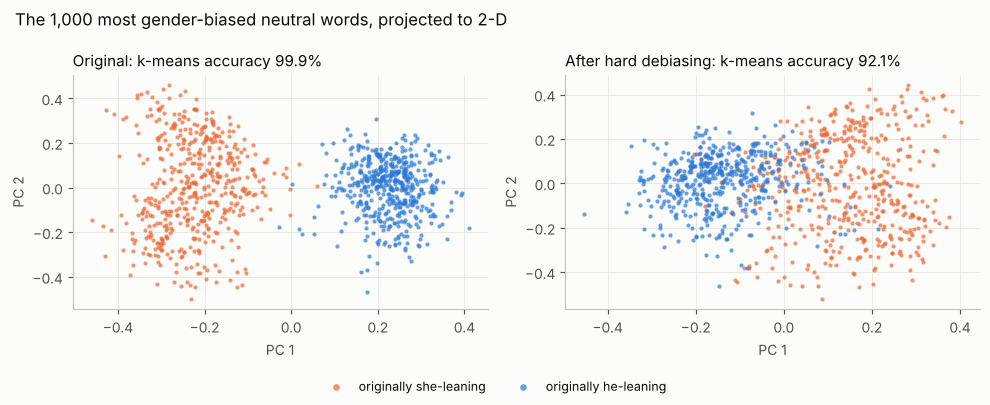

,Expected (paper),Observed,Verdict
Quantity,,,
Cluster accuracy before debiasing (G&G: GloVe),99.9%,99.9%,n/a (different embedding)
Cluster accuracy after hard debiasing (G&G: GloVe),92.5%,92.1%,n/a (different embedding)
Bias still recoverable after debiasing (well above 50%),yes,yes,match


In [28]:
he_she = unit(vec("he") - vec("she"))
neutral_idx = np.where(neutral_mask)[0]
bias_orig = V[neutral_idx] @ he_she
order = np.argsort(bias_orig)
female_idx, male_idx = neutral_idx[order[:500]], neutral_idx[order[-500:]]
chosen = np.concatenate([female_idx, male_idx])
labels = np.array([0] * 500 + [1] * 500)


def cluster_accuracy(M):
    km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(M[chosen])
    acc = np.mean(km.labels_ == labels)
    return max(acc, 1 - acc)


acc_before = cluster_accuracy(V)
acc_after = cluster_accuracy(V_hard)
print("Most she-leaning examples:", [words[i] for i in female_idx[:10]])
print("Most he-leaning examples :", [words[i] for i in male_idx[-10:]])

pca2 = PCA(n_components=2, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, M, title in [(axes[0], V, "Original"), (axes[1], V_hard, "After hard debiasing")]:
    coords = pca2.fit_transform(M[chosen])
    ax.scatter(*coords[labels == 0].T, s=9, color=ORANGE, alpha=0.7, label="originally she-leaning", linewidths=0)
    ax.scatter(*coords[labels == 1].T, s=9, color=BLUE, alpha=0.7, label="originally he-leaning", linewidths=0)
    ax.set_title(f"{title}: k-means accuracy {cluster_accuracy(M):.1%}", fontsize=11, loc="left")
    ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
fig.suptitle("The 1,000 most gender-biased neutral words, projected to 2-D", x=0.02, ha="left", fontsize=12)
plt.tight_layout(rect=(0, 0.07, 1, 1))
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=2, frameon=False, fontsize=9, markerscale=1.6)
plt.show()

compare([
    ("Cluster accuracy before debiasing (G&G: GloVe)", "99.9%", f"{acc_before:.1%}", "n/a (different embedding)"),
    ("Cluster accuracy after hard debiasing (G&G: GloVe)", "92.5%", f"{acc_after:.1%}", "n/a (different embedding)"),
    ("Bias still recoverable after debiasing (well above 50%)", "yes", "yes" if acc_after > 0.75 else "no",
     verdict("yes" if acc_after > 0.75 else "no", "yes")),
])

**Interpretation.** Before debiasing, the two groups separate almost perfectly (99.9%), which is unsurprising since we chose them by their gender projection. After hard debiasing, accuracy is still about 92%, strikingly close to the 92.5% Gonen and Goldberg report for GloVe, even though our embedding is word2vec. Every one of these words now has **zero** projection on $g$, yet $k$-means still sorts them into she-leaning and he-leaning groups far above the 50% chance level. The scatter plots show why: the groups stay apart in directions other than $g$. Gender was spread across many correlated directions, and removing one direction removed the most visible part of it, not all of it.

This supports Gonen and Goldberg's conclusion and refines the synthesis above. Bolukbasi et al.'s **measurement** of bias holds up, and their hard-debiasing method does what it promises *with respect to $g$*. But "DirectBias = 0" does not mean "gender-free." Debiasing a single direction is closer to putting lipstick on the problem than to solving it.

---
## Reproducibility notes

* **Seeds.** `SEED = 2016` seeds Python's `random`, NumPy's global generator, the `default_rng` used for the Figure 6 baseline and the soft-debiasing sample, and every scikit-learn estimator (`random_state=SEED`).
* **Caches.** Expensive results live in `cache/` (embedding in native gensim format, Equation 1 analogy lists, hard-debiased vectors, SDP solutions, and Mikolov evaluations). Delete `cache/` to recompute everything from scratch.
* **Pinned inputs.** Word lists come from `tolga-b/debiaswe` at commit `6bb03ee2`, and the analogy test set comes from the installed gensim's test data.
* **Known sources of small gaps** (listed where they arise): the released `professions.json` has 320 entries versus 327 in the paper; the paper does not state the gender direction used for Figure 3, the vocabulary cutoff for the Mikolov evaluation, or the normalization behind $\lambda$ in the SDP; and tie-breaking differs for Bolukbasi scores that are exactly zero.

In [29]:
print(f"Python {platform.python_version()} on {platform.platform()}")
for mod in (np, scipy, sklearn, pd, matplotlib, gensim):
    print(f"{mod.__name__:<12} {mod.__version__}")
print("cvxpy       ", cp.__version__)
print("debiaswe commit", subprocess.run(["git", "-C", str(DEBIASWE_DIR), "rev-parse", "HEAD"],
                                         capture_output=True, text=True).stdout.strip())

Python 3.11.17 on Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
numpy        2.4.6
scipy        1.17.1
sklearn      1.9.1
pandas       3.0.6
matplotlib   3.11.2
gensim       4.4.0
cvxpy        1.9.3
debiaswe commit 6bb03ee2a0d7214339e513ca71cd0a99069dc29c


## References

Original ideas cited in this notebook, in alphabetical order.

* Bolukbasi, T., Chang, K.-W., Zou, J. Y., Saligrama, V., and Kalai, A. T. (2016). Man is to computer programmer as woman is to homemaker? Debiasing word embeddings. *Advances in Neural Information Processing Systems 29*, 4349 to 4357. arXiv:1607.06520. Code: github.com/tolga-b/debiaswe.
* Caliskan, A., Bryson, J. J., and Narayanan, A. (2017). Semantics derived automatically from language corpora contain human-like biases. *Science*, 356(6334), 183 to 186.
* Gonen, H., and Goldberg, Y. (2019). Lipstick on a pig: Debiasing methods cover up systematic gender biases in word embeddings but do not remove them. *Proceedings of NAACL-HLT 2019*, 609 to 614.
* Hotelling, H. (1933). Analysis of a complex of statistical variables into principal components. *Journal of Educational Psychology*, 24(6), 417 to 441. (Principal component analysis; see also Pearson, 1901.)
* Levy, O., and Goldberg, Y. (2014). Linguistic regularities in sparse and explicit word representations. *Proceedings of CoNLL 2014*, 171 to 180. (3CosMul.)
* Linzen, T. (2016). Issues in evaluating semantic spaces using word analogies. *Proceedings of the 1st Workshop on Evaluating Vector-Space Representations for NLP*, 13 to 18.
* MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability*, 1, 281 to 297. ($k$-means.)
* Manzini, T., Lim, Y. C., Tsvetkov, Y., and Black, A. W. (2019). Black is to criminal as Caucasian is to police: Detecting and removing multiclass bias in word embeddings. *Proceedings of NAACL-HLT 2019*, 615 to 621. (Also arXiv:1904.04047 v2 and v3.)
* Mikolov, T., Chen, K., Corrado, G., and Dean, J. (2013a). Efficient estimation of word representations in vector space. *ICLR Workshop*. (The `questions-words.txt` test set.)
* Mikolov, T., Sutskever, I., Chen, K., Corrado, G., and Dean, J. (2013b). Distributed representations of words and phrases and their compositionality. *Advances in Neural Information Processing Systems 26*. (The GoogleNews vectors.)
* Mikolov, T., Yih, W., and Zweig, G. (2013c). Linguistic regularities in continuous space word representations. *Proceedings of NAACL-HLT 2013*, 746 to 751. (The vector-offset analogy method, later called 3CosAdd.)
* Nissim, M., van Noord, R., and van der Goot, R. (2020). Fair is better than sensational: Man is to doctor as woman is to doctor. *Computational Linguistics*, 46(2), 487 to 497. doi:10.1162/coli_a_00379.
* O'Donoghue, B., Chu, E., Parikh, N., and Boyd, S. (2016). Conic optimization via operator splitting and homogeneous self-dual embedding. *Journal of Optimization Theory and Applications*, 169(3), 1042 to 1068. (The SCS solver.)
* Pearson, K. (1901). On lines and planes of closest fit to systems of points in space. *Philosophical Magazine*, 2(11), 559 to 572.
* Řehůřek, R., and Sojka, P. (2010). Software framework for topic modelling with large corpora. *Proceedings of the LREC 2010 Workshop on New Challenges for NLP Frameworks*, 45 to 50. (gensim.)
* Diamond, S., and Boyd, S. (2016). CVXPY: A Python-embedded modeling language for convex optimization. *Journal of Machine Learning Research*, 17(83), 1 to 5.